# CatBoost for Crypto Price Prediction: A Comprehensive Seminar

**Seminar Companion to Tree Boosting Lecture**

This notebook demonstrates advanced gradient boosting techniques using CatBoost on a real-world crypto market prediction task from DRW's Kaggle competition. We'll explore:

1. **Data exploration** with Polars - market microstructure visualization
2. **CatBoost fundamentals** - parameters, tree policies, regularization
3. **Custom loss functions** - implementing Tweedie and asymmetric losses with gradients/Hessians
4. **Feature selection** - multiple approaches for high-dimensional data
5. **Trading simulation** - backtesting predictions with Sharpe ratio and PnL
6. **Advanced training** - CV, early stopping, hyperparameter tuning

---

## 0. Setup and Imports

### 0.1 Requirements and Data Access

- Python packages: `catboost`, `polars`, `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-learn`.
- Data path: update `DATA_PATH` to your local Kaggle DRW crypto dataset location.

In [27]:
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from sklearn.inspection import PartialDependenceDisplay
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# For reproducibility
np.random.seed(42)

# Configuration: Use subset for faster research, full data for final model
USE_SUBSET = True  # Set to False for final model training
SUBSET_ROWS = 100_000  # ~100k rows for fast iteration (vs 525k full)

print("Setup complete!")
print(f"Mode: {'SUBSET ({:,} rows)'.format(SUBSET_ROWS) if USE_SUBSET else 'FULL DATA'}")

Setup complete!
Mode: SUBSET (100,000 rows)


---

## 1. Data Loading and Exploration with Polars

### 1.1 Loading the DRW Crypto Competition Data

**Data caveats (please verify for your local copy):**
- Label definition and horizon are competition-specific; confirm what `label` represents.
- Sampling interval is not guaranteed to be 1 minute; treat rows as evenly spaced unless you verify timestamps.
- This notebook treats `label` as a return proxy for intuition only.

In [28]:
DATA_PATH = "/kaggle/input/drw-crypto-market-prediction/train.parquet"

# Scan to understand structure
df_lazy = pl.scan_parquet(DATA_PATH)
schema = df_lazy.collect_schema()
print("Dataset Schema:")
print(f"  Total columns: {len(schema)}")
print(f"  Proprietary features (X*): {sum(1 for c in schema if c.startswith('X'))}")
print(f"  Market data: bid_qty, ask_qty, buy_qty, sell_qty, volume")
print(f"  Target: label (future price movement)")

# Load data (subset or full based on configuration)
if USE_SUBSET:
    df = pl.read_parquet(DATA_PATH, n_rows=SUBSET_ROWS)
    print(f"\nLoaded SUBSET: {len(df):,} rows ({df.estimated_size('mb'):.1f} MB)")
else:
    df = pl.read_parquet(DATA_PATH)
    print(f"\nLoaded FULL: {len(df):,} rows ({df.estimated_size('mb'):.1f} MB)")

datetime_col = "__index_level_0__"
print(f"Time range: {df[datetime_col].min()} to {df[datetime_col].max()}")

Dataset Schema:
  Total columns: 787
  Proprietary features (X*): 780
  Market data: bid_qty, ask_qty, buy_qty, sell_qty, volume
  Target: label (future price movement)

Loaded SUBSET: 100,000 rows (600.4 MB)
Time range: 2023-03-01 00:00:00 to 2023-05-09 13:09:00


### 1.2 Market Microstructure Visualization

Let's visualize the bid/ask quantities and volume - these represent real market microstructure:

In [29]:
df.head()

bid_qty,ask_qty,buy_qty,sell_qty,volume,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,X24,X25,X26,X27,X28,X29,X30,X31,X32,…,X746,X747,X748,X749,X750,X751,X752,X753,X754,X755,X756,X757,X758,X759,X760,X761,X762,X763,X764,X765,X766,X767,X768,X769,X770,X771,X772,X773,X774,X775,X776,X777,X778,X779,X780,label,__index_level_0__
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,datetime[ns]
15.283,8.425,176.405,44.984,221.389,0.181844,-0.63786,0.006652,0.13687,0.116698,0.050156,0.063408,0.118437,1.498981,-0.058392,0.475105,0.598075,0.717269,1.128574,1.321473,1.415325,1.198338,0.988161,1.001487,1.028461,1.122363,1.026122,0.821888,0.629524,0.27941,1.941451,1.714323,1.625849,1.557562,1.108448,0.765369,0.519689,…,-0.435567,-0.854828,-0.194054,-0.386767,0.674001,0.000617,-0.532319,0.177538,0.617716,-0.625626,0.893549,-0.704807,-0.730939,0.3634,0.931868,0.577068,0.082875,-0.40738,-0.407366,-0.298108,-0.108466,0.040206,-0.033984,-0.178848,-0.596781,-0.868048,0.333753,-0.009992,-0.695595,-0.444077,-0.191238,-0.184251,-0.471897,-0.625428,-0.553991,0.562539,2023-03-01 00:00:00
38.59,2.336,525.846,321.95,847.796,0.489497,-0.075619,0.431594,0.5224,0.475255,0.380645,0.383859,0.433238,1.36439,-0.362606,0.218235,0.379769,0.528161,0.96849,1.172063,1.272317,1.127601,0.471929,0.671031,0.776974,0.927885,0.892181,0.711133,0.533984,0.235119,1.385692,1.396133,1.395087,1.386407,0.997484,0.67678,0.446211,…,-0.33332,-0.653188,-0.148285,-0.295761,0.697475,0.013388,-0.441827,0.196659,0.600366,-0.228665,0.746898,-0.673748,-0.725971,0.152737,0.863999,0.574423,0.053245,-0.281884,-0.356342,-0.271037,-0.094401,0.046163,-0.030115,-0.176216,0.040433,0.194182,0.333657,-0.01004,-0.696226,-0.452866,-0.200082,-0.188929,-0.472842,-0.625832,-0.554426,0.533686,2023-03-01 00:01:00
0.442,60.25,159.227,136.369,295.596,0.260121,-0.444684,0.100695,0.224729,0.203282,0.133086,0.144343,0.198171,1.282766,-0.517351,0.064711,0.247097,0.412706,0.870619,1.080938,1.185302,1.096584,0.242067,0.518657,0.661361,0.839011,0.832225,0.662083,0.491913,0.21066,1.050281,1.205921,1.259501,1.28754,0.935137,0.627506,0.405523,…,-0.25306,-0.494909,-0.112477,-0.224561,0.641859,-0.016807,-0.65519,0.164372,0.545954,-0.142201,0.69909,-0.669792,-0.725973,-0.227066,0.865297,0.571785,0.052404,-0.273205,-0.352048,-0.270775,-0.096075,0.04493,-0.030757,-0.176536,0.096702,0.270557,0.333667,-0.010037,-0.696832,-0.461383,-0.208786,-0.193571,-0.473785,-0.626236,-0.55486,0.546505,2023-03-01 00:02:00
4.865,21.016,335.742,124.963,460.705,0.099976,-0.666728,-0.123858,0.019197,0.014459,-0.039387,-0.02271,0.034124,1.026768,-1.05905,-0.396807,-0.153537,0.060875,0.569664,0.798739,0.914339,1.103646,0.26265,0.531703,0.673951,0.850572,0.843011,0.672109,0.501067,0.253203,1.31911,1.419536,1.434907,1.428934,1.036181,0.710706,0.475472,…,-0.10048,-0.194009,-0.04497,-0.090331,0.605352,-0.036622,-0.795052,0.152298,0.496609,-0.215346,0.644114,-0.66587,-0.725976,-0.141912,0.939656,0.569153,0.037516,-0.233802,-0.334414,-0.262636,-0.093064,0.045845,-0.030052,-0.175974,0.153069,0.425835,0.333174,-0.010279,-0.697391,-0.469628,-0.21735,-0.198175,-0.474726,-0.626639,-0.555294,0.357703,2023-03-01 00:03:00
27.158,3.451,98.411,44.407,142.818,0.270893,-0.325973,0.116336,0.234311,0.214073,0.144404,0.155398,0.209035,1.075057,-0.851712,-0.297338,-0.076207,0.126099,0.624402,0.850581,0.964662,1.108776,0.269714,0.536185,0.679926,0.856979,0.850185,0.679127,0.507617,0.259132,1.249968,1.408936,1.438707,1.438313,1.047752,0.721435,0.484928,…,-0.016742,-0.02887,-0.008207,-0.017233,0.57458,-0.053322,-0.912802,0.165338,0.51192,-0.250744,0.649571,-0.662004,-0.725978,0.272477,0.914417,0.566529,0.040455,-0.258651,-0.343296,-0.269806,-0.099072,0.042628,-0.031941,-0.17711,0.151156,0.44505,0

In [30]:
df.select()

shape: (0, 0)
┌┐
╞╡
└┘

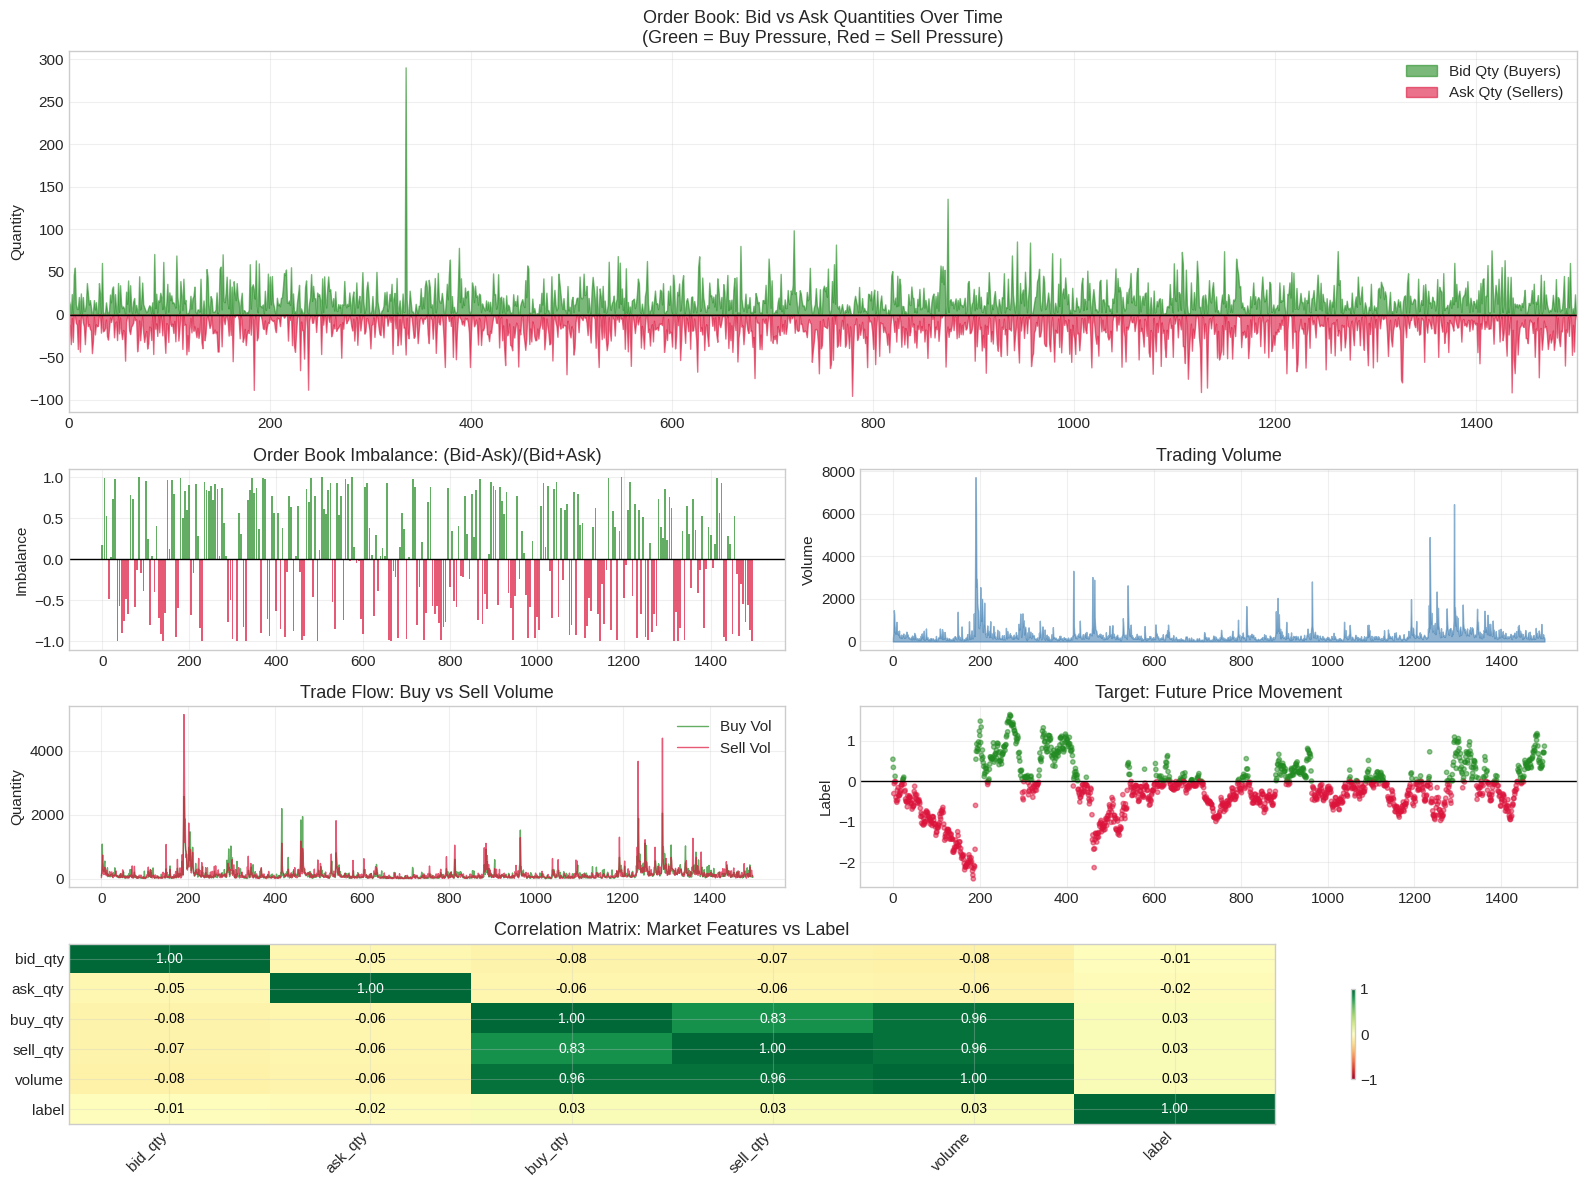

In [31]:
# Market data visualization - a beautiful slice of the order book dynamics
fig = plt.figure(figsize=(16, 12))

# Take a representative slice for visualization
slice_start = 1000
slice_end = 2500
slice_df = df[slice_start:slice_end]
time_idx = np.arange(len(slice_df))

# Create custom colormap for bid/ask
colors_bid = plt.cm.Greens(np.linspace(0.4, 0.8, 256))
colors_ask = plt.cm.Reds(np.linspace(0.4, 0.8, 256))

gs = GridSpec(4, 2, figure=fig, height_ratios=[2, 1, 1, 1])

# 1. Bid vs Ask Quantity (Order Book Imbalance)
ax1 = fig.add_subplot(gs[0, :])
bid_qty = slice_df["bid_qty"].to_numpy()
ask_qty = slice_df["ask_qty"].to_numpy()

ax1.fill_between(time_idx, 0, bid_qty, alpha=0.6, color='forestgreen', label='Bid Qty (Buyers)')
ax1.fill_between(time_idx, 0, -ask_qty, alpha=0.6, color='crimson', label='Ask Qty (Sellers)')
ax1.axhline(0, color='black', linewidth=1)
ax1.set_ylabel("Quantity")
ax1.set_title("Order Book: Bid vs Ask Quantities Over Time\n(Green = Buy Pressure, Red = Sell Pressure)")
ax1.legend(loc='upper right')
ax1.set_xlim(0, len(time_idx))

# 2. Order Book Imbalance (normalized)
ax2 = fig.add_subplot(gs[1, 0])
imbalance = (bid_qty - ask_qty) / (bid_qty + ask_qty + 1e-8)
colors = ['forestgreen' if x > 0 else 'crimson' for x in imbalance]
ax2.bar(time_idx[::5], imbalance[::5], color=colors[::5], alpha=0.7, width=4)
ax2.axhline(0, color='black', linewidth=1)
ax2.set_ylabel("Imbalance")
ax2.set_title("Order Book Imbalance: (Bid-Ask)/(Bid+Ask)")

# 3. Volume
ax3 = fig.add_subplot(gs[1, 1])
volume = slice_df["volume"].to_numpy()
ax3.fill_between(time_idx, 0, volume, alpha=0.6, color='steelblue')
ax3.set_ylabel("Volume")
ax3.set_title("Trading Volume")

# 4. Buy vs Sell Quantity (Trade Flow)
ax4 = fig.add_subplot(gs[2, 0])
buy_qty = slice_df["buy_qty"].to_numpy()
sell_qty = slice_df["sell_qty"].to_numpy()
ax4.plot(time_idx, buy_qty, alpha=0.7, color='forestgreen', label='Buy Vol', linewidth=1)
ax4.plot(time_idx, sell_qty, alpha=0.7, color='crimson', label='Sell Vol', linewidth=1)
ax4.set_ylabel("Quantity")
ax4.set_title("Trade Flow: Buy vs Sell Volume")
ax4.legend()

# 5. Label (Target) - What we're predicting
ax5 = fig.add_subplot(gs[2, 1])
label = slice_df["label"].to_numpy()
colors_label = ['forestgreen' if x > 0 else 'crimson' for x in label]
ax5.scatter(time_idx, label, c=colors_label, alpha=0.5, s=10)
ax5.axhline(0, color='black', linewidth=1)
ax5.set_ylabel("Label")
ax5.set_title("Target: Future Price Movement")

# 6. Correlation heatmap: Market features vs Label
ax6 = fig.add_subplot(gs[3, :])
market_cols = ['bid_qty', 'ask_qty', 'buy_qty', 'sell_qty', 'volume', 'label']
corr_data = df.select(market_cols).to_numpy()
corr_matrix = np.corrcoef(corr_data.T)

im = ax6.imshow(corr_matrix, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
ax6.set_xticks(range(len(market_cols)))
ax6.set_yticks(range(len(market_cols)))
ax6.set_xticklabels(market_cols, rotation=45, ha='right')
ax6.set_yticklabels(market_cols)
ax6.set_title("Correlation Matrix: Market Features vs Label")

# Add correlation values as text
for i in range(len(market_cols)):
    for j in range(len(market_cols)):
        ax6.text(j, i, f'{corr_matrix[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(corr_matrix[i,j]) > 0.5 else 'black', fontsize=10)

plt.colorbar(im, ax=ax6, shrink=0.5)
plt.tight_layout()
plt.show()

### 1.3 Target Distribution and Statistics

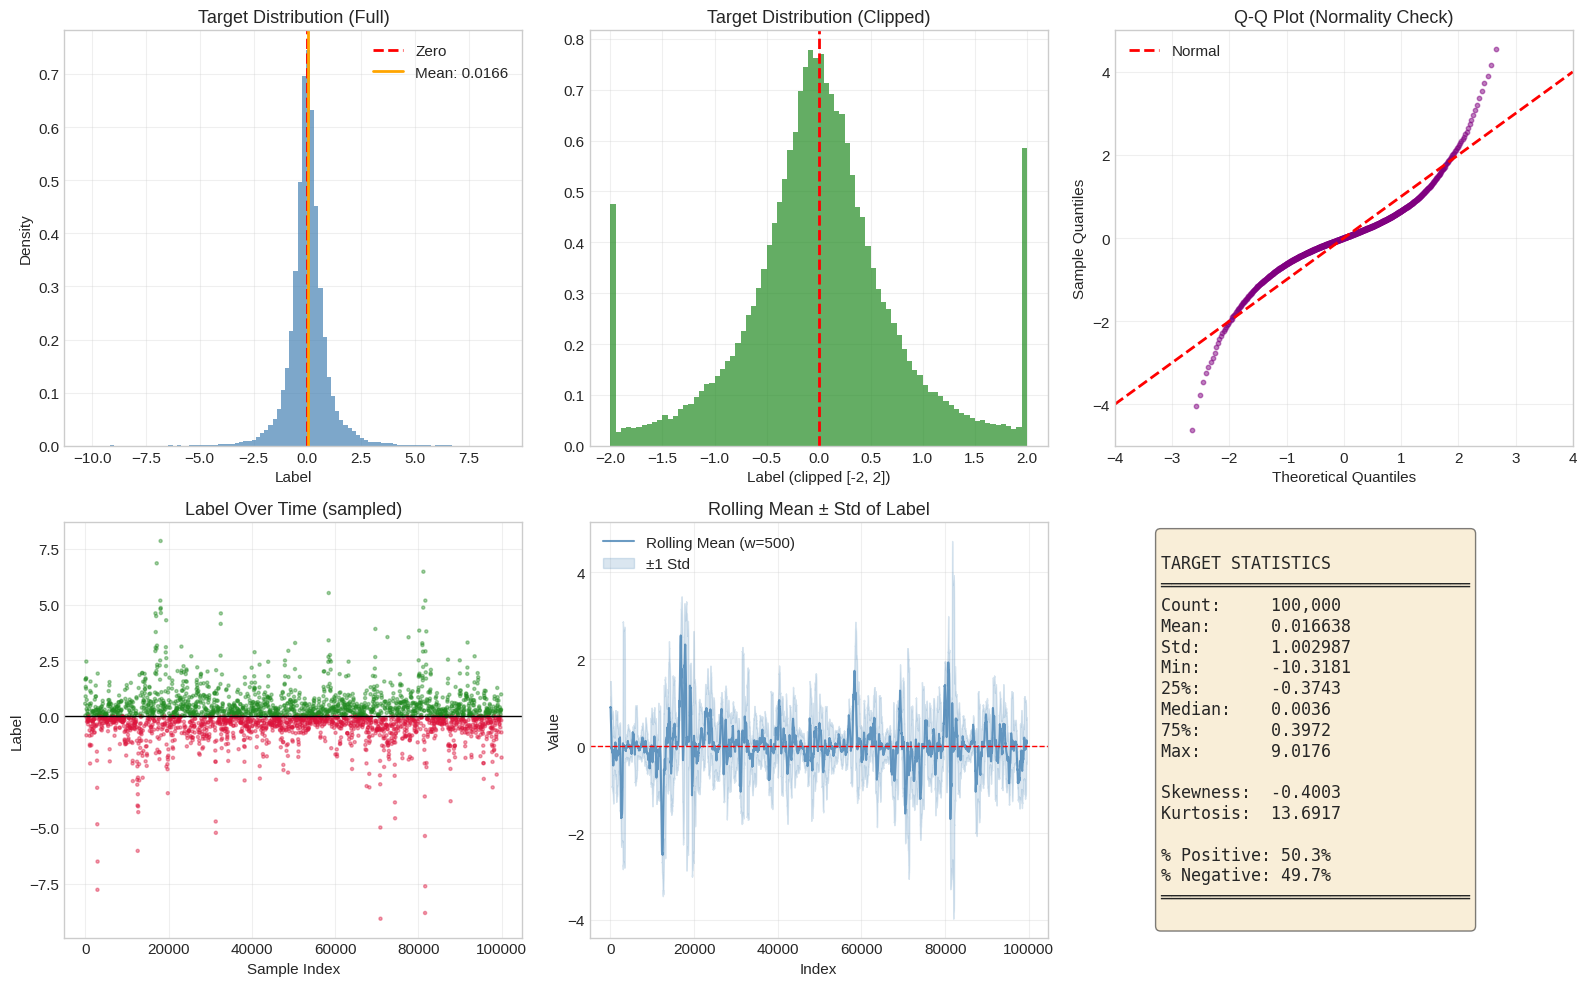

In [32]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

labels = df["label"].to_numpy()

# 1. Full histogram
ax = axes[0, 0]
ax.hist(labels, bins=100, edgecolor='none', alpha=0.7, color='steelblue', density=True)
ax.axvline(0, color='red', linestyle='--', linewidth=2, label='Zero')
ax.axvline(np.mean(labels), color='orange', linewidth=2, label=f'Mean: {np.mean(labels):.4f}')
ax.set_xlabel("Label")
ax.set_ylabel("Density")
ax.set_title("Target Distribution (Full)")
ax.legend()

# 2. Clipped histogram for detail
ax = axes[0, 1]
clipped = np.clip(labels, -2, 2)
ax.hist(clipped, bins=80, edgecolor='none', alpha=0.7, color='forestgreen', density=True)
ax.axvline(0, color='red', linestyle='--', linewidth=2)
ax.set_xlabel("Label (clipped [-2, 2])")
ax.set_title("Target Distribution (Clipped)")

# 3. QQ plot for normality check
ax = axes[0, 2]
sorted_labels = np.sort(labels)
n = len(sorted_labels)
theoretical_quantiles = np.linspace(0.001, 0.999, n)
from scipy import stats
normal_quantiles = stats.norm.ppf(theoretical_quantiles)
ax.scatter(normal_quantiles[::100], sorted_labels[::100], alpha=0.5, s=10, c='purple')
ax.plot([-4, 4], [-4, 4], 'r--', linewidth=2, label='Normal')
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
ax.set_title("Q-Q Plot (Normality Check)")
ax.legend()
ax.set_xlim(-4, 4)
ax.set_ylim(-5, 5)

# 4. Label over time
ax = axes[1, 0]
sample_idx = np.linspace(0, len(labels)-1, min(3000, len(labels)), dtype=int)
colors = ['forestgreen' if labels[i] > 0 else 'crimson' for i in sample_idx]
ax.scatter(sample_idx, labels[sample_idx], c=colors, alpha=0.4, s=5)
ax.axhline(0, color='black', linewidth=1)
ax.set_xlabel("Sample Index")
ax.set_ylabel("Label")
ax.set_title("Label Over Time (sampled)")

# 5. Rolling statistics
ax = axes[1, 1]
window = 500
rolling_mean = np.convolve(labels, np.ones(window)/window, mode='valid')
rolling_std = np.array([np.std(labels[max(0,i-window):i+1]) for i in range(len(labels))])
ax.plot(rolling_mean, alpha=0.8, color='steelblue', label=f'Rolling Mean (w={window})')
ax.fill_between(range(len(rolling_mean)),
                rolling_mean - rolling_std[:len(rolling_mean)],
                rolling_mean + rolling_std[:len(rolling_mean)],
                alpha=0.2, color='steelblue', label='±1 Std')
ax.axhline(0, color='red', linestyle='--', linewidth=1)
ax.set_xlabel("Index")
ax.set_ylabel("Value")
ax.set_title("Rolling Mean ± Std of Label")
ax.legend()

# 6. Statistics box
ax = axes[1, 2]
ax.axis('off')
stats_text = f"""
TARGET STATISTICS
═══════════════════════════════
Count:     {len(labels):,}
Mean:      {np.mean(labels):.6f}
Std:       {np.std(labels):.6f}
Min:       {np.min(labels):.4f}
25%:       {np.percentile(labels, 25):.4f}
Median:    {np.median(labels):.4f}
75%:       {np.percentile(labels, 75):.4f}
Max:       {np.max(labels):.4f}

Skewness:  {stats.skew(labels):.4f}
Kurtosis:  {stats.kurtosis(labels):.4f}

% Positive: {np.mean(labels > 0)*100:.1f}%
% Negative: {np.mean(labels < 0)*100:.1f}%
═══════════════════════════════
"""
ax.text(0.1, 0.5, stats_text, transform=ax.transAxes, fontsize=12,
        verticalalignment='center', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

---

## 2. Train/Validation/Test Split Strategy

For time-series data, we MUST respect temporal order. We'll use:
- **Train**: First 60% of data
- **Validation**: Next 20% (for early stopping, hyperparameter tuning)
- **Test**: Final 20% (held out, only touched at the end)

In [33]:
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Prepare features and target
feature_cols = [c for c in df.columns if c not in ["label", datetime_col]]
X = df.select(feature_cols).to_numpy()
y = df["label"].to_numpy()
timestamps = df[datetime_col].to_numpy()

print(f"Total samples: {len(y):,}")
print(f"Total features: {len(feature_cols)}")

# Time-aware split
n_samples = len(y)
train_end = int(0.6 * n_samples)
val_end = int(0.8 * n_samples)

X_train, y_train = X[:train_end], y[:train_end]
X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[val_end:], y[val_end:]
ts_train, ts_val, ts_test = timestamps[:train_end], timestamps[train_end:val_end], timestamps[val_end:]

print(f"\nSplit sizes:")
print(f"  Train:      {len(y_train):>8,} samples ({len(y_train)/n_samples*100:.1f}%)")
print(f"  Validation: {len(y_val):>8,} samples ({len(y_val)/n_samples*100:.1f}%)")
print(f"  Test:       {len(y_test):>8,} samples ({len(y_test)/n_samples*100:.1f}%)")

# Create CatBoost Pools
train_pool = Pool(X_train, y_train, feature_names=feature_cols)
val_pool = Pool(X_val, y_val, feature_names=feature_cols)
test_pool = Pool(X_test, y_test, feature_names=feature_cols)

Total samples: 100,000
Total features: 785

Split sizes:
  Train:        60,000 samples (60.0%)
  Validation:   20,000 samples (20.0%)
  Test:         20,000 samples (20.0%)


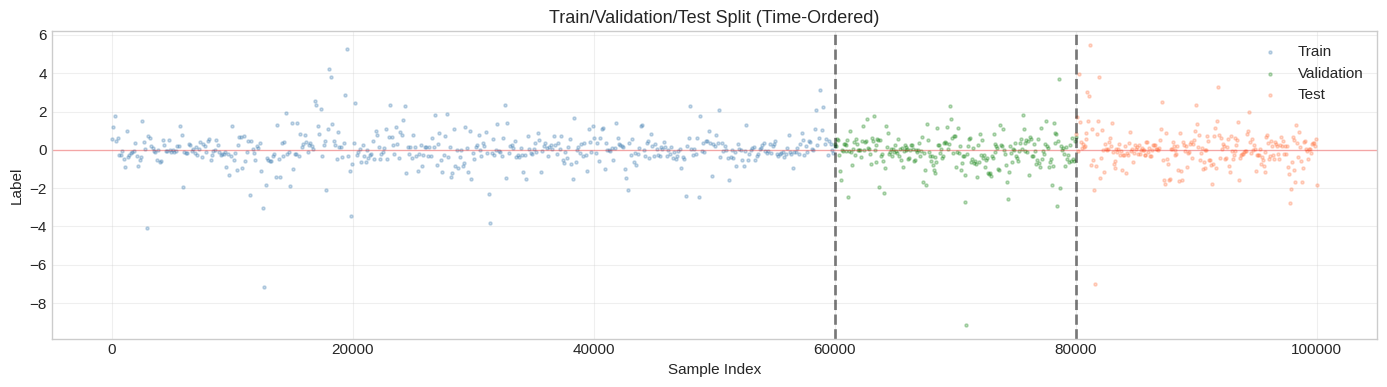

In [34]:
# Visualize the split
fig, ax = plt.subplots(figsize=(14, 4))

# Plot labels for each split with different colors
n_plot = min(500, len(y_train))
train_idx = np.linspace(0, len(y_train)-1, n_plot, dtype=int)
val_idx = np.linspace(0, len(y_val)-1, n_plot//2, dtype=int)
test_idx = np.linspace(0, len(y_test)-1, n_plot//2, dtype=int)

ax.scatter(train_idx, y_train[train_idx], alpha=0.3, s=5, c='steelblue', label='Train')
ax.scatter(val_idx + len(y_train), y_val[val_idx], alpha=0.3, s=5, c='forestgreen', label='Validation')
ax.scatter(test_idx + len(y_train) + len(y_val), y_test[test_idx], alpha=0.3, s=5, c='coral', label='Test')

ax.axvline(len(y_train), color='black', linestyle='--', linewidth=2, alpha=0.5)
ax.axvline(len(y_train) + len(y_val), color='black', linestyle='--', linewidth=2, alpha=0.5)
ax.axhline(0, color='red', linestyle='-', linewidth=1, alpha=0.3)

ax.set_xlabel("Sample Index")
ax.set_ylabel("Label")
ax.set_title("Train/Validation/Test Split (Time-Ordered)")
ax.legend()
plt.tight_layout()
plt.show()

---

## 3. CatBoost Parameters Deep Dive

### 3.1 Key Parameters Reference

| Area | Parameter | Meaning | Notes |
| --- | --- | --- | --- |
| Tree structure | `depth` (default=6) | Max tree depth | Higher = more complex |
| Tree structure | `max_leaves` (default=31) | Max leaves per tree | Alternative to `depth` |
| Tree structure | `min_data_in_leaf` (default=1) | Min samples per leaf | Regularizes small leaves |
| Tree structure | `min_child_weight` (derived) | Min sum of Hessians in child | For RMSE, H=1 so this mirrors `min_data_in_leaf`; for LogLoss, H=p(1-p) so it controls effective samples |
| Grow policy | `grow_policy='SymmetricTree'` | Oblivious trees | Same split each level; fast inference; CatBoost default |
| Grow policy | `grow_policy='Depthwise'` | Level-wise growth | Similar to LightGBM |
| Grow policy | `grow_policy='Lossguide'` | Leaf-wise growth | Similar to XGBoost; more expressive, higher overfit risk |
| Boosting | `iterations` (default=1000) | Number of boosting rounds | Upper bound; with early stopping, best iteration is usually lower |
| Boosting | `learning_rate` (default=0.03) | Shrinkage factor η | Lower = slower but often better |
| Boosting | `early_stopping_rounds` | Stop when eval set stops improving | Requires validation set |
| Regularization | `l2_leaf_reg` (default=3) | L2 penalty on leaf weights | w* = -G/(H+λ) |
| Regularization | `random_strength` (default=1) | Noise on leaf scores | Stabilizes training |
| Regularization | `bagging_temperature` | Bayesian bootstrap strength | Higher = more randomness |
| Regularization | `subsample` | Fraction of rows per tree | Stochastic boosting |
| Regularization | `rsm` / `colsample_bylevel` | Fraction of features per split | Feature subsampling |

### 3.2 Understanding min_child_weight and Leaf Constraints

In [35]:
train_pool.shape

(60000, 785)

Testing min_data_in_leaf values...
  min_data_in_leaf=0.001: val_rmse=0.933576
  min_data_in_leaf=0.01: val_rmse=0.933439
  min_data_in_leaf=0.05: val_rmse=0.937269
  min_data_in_leaf=0.1: val_rmse=0.936152


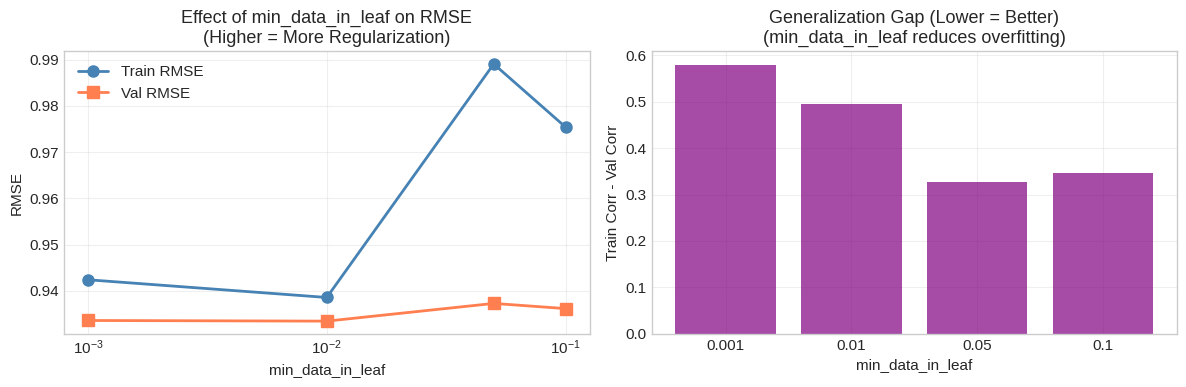

In [36]:
# Demonstrate min_data_in_leaf effect
min_data_values = [0.001, 0.01, 0.05, 0.1]
min_data_results = {}

print("Testing min_data_in_leaf values...")
for min_data in min_data_values:
    model = CatBoostRegressor(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        grow_policy='Depthwise',
        l2_leaf_reg=3,
        min_data_in_leaf=int(train_pool.shape[0] * min_data),
        loss_function='RMSE',
        random_seed=42,
        verbose=False,
        early_stopping_rounds=30,
    )
    model.fit(train_pool, eval_set=val_pool, use_best_model=True, plot=False)

    train_preds = model.predict(X_train)
    val_preds = model.predict(X_val)

    min_data_results[min_data] = {
        'train_rmse': np.sqrt(mean_squared_error(y_train, train_preds)),
        'val_rmse': np.sqrt(mean_squared_error(y_val, val_preds)),
        'train_corr': np.corrcoef(y_train, train_preds)[0, 1],
        'val_corr': np.corrcoef(y_val, val_preds)[0, 1],
        'best_iter': model.get_best_iteration(),
    }
    print(f"  min_data_in_leaf={min_data:>3}: val_rmse={min_data_results[min_data]['val_rmse']:.6f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

min_data_list = list(min_data_results.keys())

ax = axes[0]
train_rmse = [min_data_results[m]['train_rmse'] for m in min_data_list]
val_rmse = [min_data_results[m]['val_rmse'] for m in min_data_list]
ax.plot(min_data_list, train_rmse, 'o-', label='Train RMSE', color='steelblue', linewidth=2, markersize=8)
ax.plot(min_data_list, val_rmse, 's-', label='Val RMSE', color='coral', linewidth=2, markersize=8)
ax.set_xlabel("min_data_in_leaf")
ax.set_ylabel("RMSE")
ax.set_title("Effect of min_data_in_leaf on RMSE\n(Higher = More Regularization)")
ax.legend()
ax.set_xscale('log')

ax = axes[1]
train_corr = [min_data_results[m]['train_corr'] for m in min_data_list]
val_corr = [min_data_results[m]['val_corr'] for m in min_data_list]
gap = [t - v for t, v in zip(train_corr, val_corr)]
ax.bar(range(len(min_data_list)), gap, color='purple', alpha=0.7)
ax.set_xticks(range(len(min_data_list)))
ax.set_xticklabels(min_data_list)
ax.set_xlabel("min_data_in_leaf")
ax.set_ylabel("Train Corr - Val Corr")
ax.set_title("Generalization Gap (Lower = Better)\n(min_data_in_leaf reduces overfitting)")

plt.tight_layout()
plt.show()

### 3.3 Oblivious Trees vs Lossguide: A Comparison

Comparing tree grow policies...
  SymmetricTree  : val_rmse=0.934862, best_iter=12
  Depthwise      : val_rmse=0.933857, best_iter=2
  Lossguide      : val_rmse=0.933253, best_iter=7


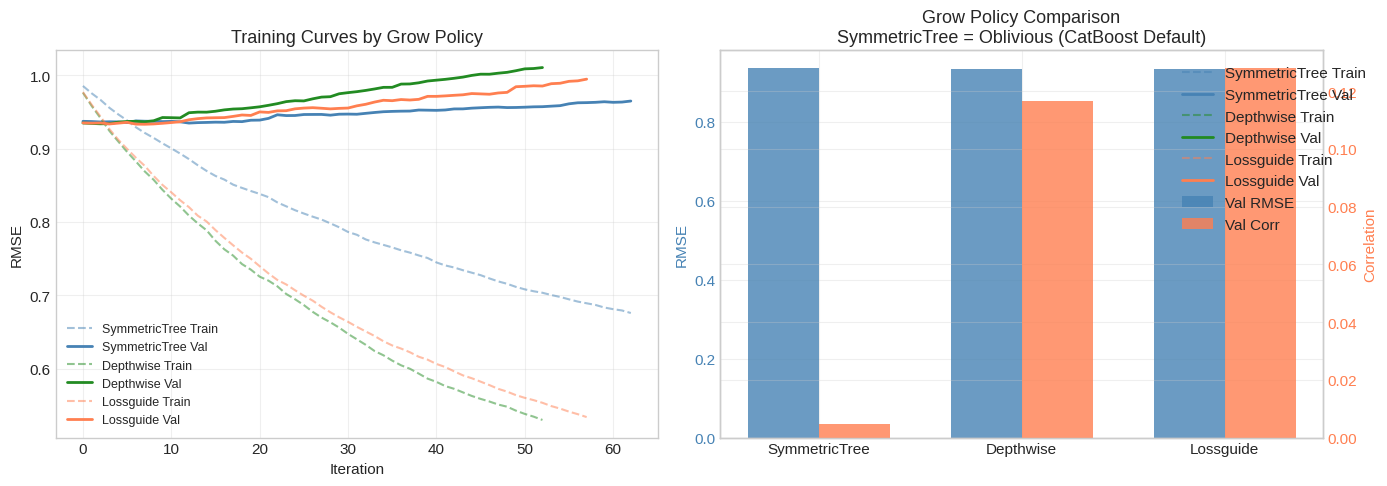


KEY INSIGHT: SymmetricTree (Oblivious Trees)

Oblivious Decision Trees use the SAME split condition at each tree level.
This means all nodes at level k split on feature j with threshold t.

Advantages:
1. Very fast inference (can evaluate level-by-level using bitwise operations)
2. Natural regularization (forces similar structure across tree)
3. Less prone to overfitting

Trade-off:
- May be less expressive than Lossguide for complex patterns
- But often generalizes better due to structural constraint



In [37]:
# Compare grow policies
grow_policies = ['SymmetricTree', 'Depthwise', 'Lossguide']
policy_results = {}
policy_histories = {}

print("Comparing tree grow policies...")
for policy in grow_policies:
    model = CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=3,
        grow_policy=policy,
        loss_function='RMSE',
        random_seed=42,
        verbose=False,
        early_stopping_rounds=50,
    )
    model.fit(train_pool, eval_set=val_pool, use_best_model=True, plot=False)

    evals = model.get_evals_result()
    policy_histories[policy] = {
        'train': evals['learn']['RMSE'],
        'val': evals['validation']['RMSE'],
    }

    val_preds = model.predict(X_val)
    policy_results[policy] = {
        'val_rmse': np.sqrt(mean_squared_error(y_val, val_preds)),
        'val_corr': np.corrcoef(y_val, val_preds)[0, 1],
        'best_iter': model.get_best_iteration(),
    }
    print(f"  {policy:15s}: val_rmse={policy_results[policy]['val_rmse']:.6f}, "
          f"best_iter={policy_results[policy]['best_iter']}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training curves
ax = axes[0]
colors = {'SymmetricTree': 'steelblue', 'Depthwise': 'forestgreen', 'Lossguide': 'coral'}
for policy, hist in policy_histories.items():
    ax.plot(hist['train'], '--', alpha=0.5, color=colors[policy], label=f'{policy} Train')
    ax.plot(hist['val'], '-', color=colors[policy], label=f'{policy} Val', linewidth=2)
ax.set_xlabel("Iteration")
ax.set_ylabel("RMSE")
ax.set_title("Training Curves by Grow Policy")
ax.legend(fontsize=9)

# Comparison bars
ax = axes[1]
policies = list(policy_results.keys())
val_rmses = [policy_results[p]['val_rmse'] for p in policies]
val_corrs = [policy_results[p]['val_corr'] for p in policies]

x = np.arange(len(policies))
width = 0.35
bars1 = ax.bar(x - width/2, val_rmses, width, label='Val RMSE', color='steelblue', alpha=0.8)
ax.set_ylabel("RMSE", color='steelblue')
ax.set_xticks(x)
ax.set_xticklabels(policies)
ax.tick_params(axis='y', labelcolor='steelblue')

ax2 = ax.twinx()
bars2 = ax2.bar(x + width/2, val_corrs, width, label='Val Corr', color='coral', alpha=0.8)
ax2.set_ylabel("Correlation", color='coral')
ax2.tick_params(axis='y', labelcolor='coral')

ax.set_title("Grow Policy Comparison\nSymmetricTree = Oblivious (CatBoost Default)")
fig.legend(loc='upper right', bbox_to_anchor=(0.99, 0.88))

plt.tight_layout()
plt.show()

print("\n" + "="*70)
print("KEY INSIGHT: SymmetricTree (Oblivious Trees)")
print("="*70)
print("""
Oblivious Decision Trees use the SAME split condition at each tree level.
This means all nodes at level k split on feature j with threshold t.

Advantages:
1. Very fast inference (can evaluate level-by-level using bitwise operations)
2. Natural regularization (forces similar structure across tree)
3. Less prone to overfitting

Trade-off:
- May be less expressive than Lossguide for complex patterns
- But often generalizes better due to structural constraint
""")

---

## 4. Custom Loss Functions with Gradient and Hessian

CatBoost allows custom objectives by providing gradient and Hessian functions. This is powerful for financial applications.

### 4.1 Understanding Custom Loss Implementation

CatBoost custom objectives are defined by providing gradients and Hessians for each example:

- We optimize via a Taylor expansion: `L(y, F + h) ≈ L(y, F) + g·h + ½·H·h²`
- `g = ∂L/∂F`, `H = ∂²L/∂F²` (H must be positive)
- Implement `calc_ders_range(approxes, targets, weights) -> [(g, H), ...]`

Examples:

| Loss | Definition | Gradient g | Hessian H |
| --- | --- | --- | --- |
| MSE | `L = ½(y-F)²` | `F - y` | `1` |
| Huber (δ) | `L = ½r²` if `|r|≤δ` else `δ(|r|-½δ)` | `-r` if `|r|≤δ` else `-δ·sign(r)` | `1` if `|r|≤δ` else small constant |
| Tweedie (p) | zero-inflated continuous data (non-negative targets) | derived from `mu=exp(F)` | positive, uses `mu**(2-p)` |
| Asymmetric (α) | penalize under/over differently | `-2αr` or `-2(1-α)r` | `2α` or `2(1-α)` |

### 4.2 Implementing Custom Losses

In [38]:
class HuberLossObjective:
    """
    Huber loss: Smooth transition between L1 and L2.
    More robust to outliers than MSE.

    L = 0.5 * r^2           if |r| <= delta
        delta * (|r| - 0.5*delta)  otherwise

    where r = y - F (residual)
    """
    def __init__(self, delta=1.0):
        self.delta = delta

    def calc_ders_range(self, approxes, targets, weights):
        """
        Calculate first and second derivatives for each sample.
        Returns list of (gradient, hessian) tuples.
        """
        # Handle case when CatBoost passes None for weights
        if weights is None:
            weights = [1.0] * len(approxes)
        result = []
        for approx, target, weight in zip(approxes, targets, weights):
            residual = target - approx  # r = y - F
            abs_r = abs(residual)

            if abs_r <= self.delta:
                # Quadratic region
                grad = -residual  # ∂L/∂F = -(y-F) = F-y
                hess = 1.0
            else:
                # Linear region
                grad = -self.delta * (1 if residual > 0 else -1)
                hess = 0.01  # Small positive constant for stability

            # Apply weight
            grad *= weight
            hess *= weight

            result.append((grad, hess))
        return result


class AsymmetricLossObjective:
    """
    Asymmetric loss: Different penalties for over/under prediction.

    L = alpha * r^2   if r > 0 (under-prediction)
        (1-alpha) * r^2  if r <= 0 (over-prediction)

    alpha > 0.5: penalize under-prediction more
    alpha < 0.5: penalize over-prediction more
    """
    def __init__(self, alpha=0.75):
        self.alpha = alpha

    def calc_ders_range(self, approxes, targets, weights):
        # Handle case when CatBoost passes None for weights
        if weights is None:
            weights = [1.0] * len(approxes)
        result = []
        for approx, target, weight in zip(approxes, targets, weights):
            residual = target - approx

            if residual > 0:  # Under-prediction
                grad = -2 * self.alpha * residual
                hess = 2 * self.alpha
            else:  # Over-prediction
                grad = -2 * (1 - self.alpha) * residual
                hess = 2 * (1 - self.alpha)

            grad *= weight
            hess *= weight
            result.append((grad, hess))
        return result


class TweedieLossObjective:
    """
    Tweedie loss: For zero-inflated continuous targets.
    Useful when target has point mass at zero plus continuous positive values.

    Power parameter p:
    - p=1: Poisson-like
    - p=2: Gamma-like
    - 1<p<2: Compound Poisson-Gamma

    For simplicity, we use the log-link formulation:
    L = -y*F^(1-p)/(1-p) + F^(2-p)/(2-p)  where F = exp(raw_pred)
    """
    def __init__(self, p=1.5):
        self.p = p
        assert 1 < p < 2, "Tweedie power p must be in (1, 2)"

    def calc_ders_range(self, approxes, targets, weights):
        # Handle case when CatBoost passes None for weights
        if weights is None:
            weights = [1.0] * len(approxes)
        result = []
        eps = 1e-8

        for approx, target, weight in zip(approxes, targets, weights):
            # Use exp link: mu = exp(approx)
            mu = np.exp(np.clip(approx, -10, 10))

            # Gradient: d/dF [-y*mu^(1-p)/(1-p) + mu^(2-p)/(2-p)]
            # After simplification with chain rule through exp:
            grad = -target * mu**(1 - self.p) + mu**(2 - self.p)

            # Hessian (approximate, always positive)
            hess = (2 - self.p) * mu**(2 - self.p) + eps

            grad *= weight
            hess *= weight
            result.append((grad, hess))
        return result


# Also need a custom metric to evaluate
class RMSEMetric:
    """Custom RMSE metric for evaluation."""

    def get_final_error(self, error, weight):
        return np.sqrt(error / weight)

    def is_max_optimal(self):
        return False

    def evaluate(self, approxes, target, weight):
        assert len(approxes) == 1
        approx = approxes[0]

        # Handle None weights (CatBoost passes None when no sample weights provided)
        if weight is None:
            weight = [1.0] * len(approx)

        error_sum = 0.0
        weight_sum = 0.0

        for a, t, w in zip(approx, target, weight):
            error_sum += w * (a - t) ** 2
            weight_sum += w

        return error_sum, weight_sum

### 4.3 Training with Custom Losses

In [39]:
# Train models with different custom losses
custom_losses = {
    'RMSE (baseline)': None,
    'Huber (δ=1.0)': HuberLossObjective(delta=1.0),
    'Huber (δ=0.5)': HuberLossObjective(delta=0.5),
    'Asymmetric (α=0.7)': AsymmetricLossObjective(alpha=0.7),
    'Asymmetric (α=0.3)': AsymmetricLossObjective(alpha=0.3),
}
# Tweedie is omitted because it assumes non-negative targets.

custom_results = {}

print("Training with custom loss functions...")
for name, loss_obj in custom_losses.items():
    print(f"  Training: {name}...")

    if loss_obj is None:
        model = CatBoostRegressor(
            iterations=200,
            learning_rate=0.05,
            depth=6,
            l2_leaf_reg=3,
            loss_function='RMSE',
            random_seed=42,
            verbose=False,
            early_stopping_rounds=30,
        )
    else:
        model = CatBoostRegressor(
            iterations=200,
            learning_rate=0.05,
            depth=6,
            l2_leaf_reg=3,
            loss_function=loss_obj,
            eval_metric=RMSEMetric(),
            random_seed=42,
            verbose=False,
            early_stopping_rounds=30,
        )

    model.fit(train_pool, eval_set=val_pool, use_best_model=True, plot=False)

    val_preds = model.predict(X_val)

    # Calculate metrics
    residuals = y_val - val_preds

    custom_results[name] = {
        'val_rmse': np.sqrt(mean_squared_error(y_val, val_preds)),
        'val_mae': mean_absolute_error(y_val, val_preds),
        'val_corr': np.corrcoef(y_val, val_preds)[0, 1],
        'preds': val_preds,
        'mean_pred': np.mean(val_preds),
        'pct_under': np.mean(residuals > 0),  # actual > pred
    }

print("\nCustom Loss Comparison:")
custom_df = pd.DataFrame(
    [
        {
            "Loss": name,
            "RMSE": res["val_rmse"],
            "MAE": res["val_mae"],
            "Corr": res["val_corr"],
            "%Under": res["pct_under"] * 100,
        }
        for name, res in custom_results.items()
    ]
).sort_values("RMSE")
custom_df

Training with custom loss functions...
  Training: RMSE (baseline)...
  Training: Huber (δ=1.0)...


Training has stopped (degenerate solution on iteration 4, probably too small l2-regularization, try to increase it)


  Training: Huber (δ=0.5)...


Training has stopped (degenerate solution on iteration 1, probably too small l2-regularization, try to increase it)


  Training: Asymmetric (α=0.7)...
  Training: Asymmetric (α=0.3)...


Training has stopped (degenerate solution on iteration 14, probably too small l2-regularization, try to increase it)



Custom Loss Comparison:


,Loss,RMSE,MAE,Corr,%Under
4,Asymmetric (α=0.3),0.917846,0.615757,0.115086,53.290
1,Huber (δ=1.0),0.926090,0.616998,0.143396,47.435
2,Huber (δ=0.5),0.928361,0.618906,0.073770,47.740
3,Asymmetric (α=0.7),0.929814,0.620727,0.010490,47.825
0,RMSE (baseline),0.934862,0.622356,0.004608,46.485


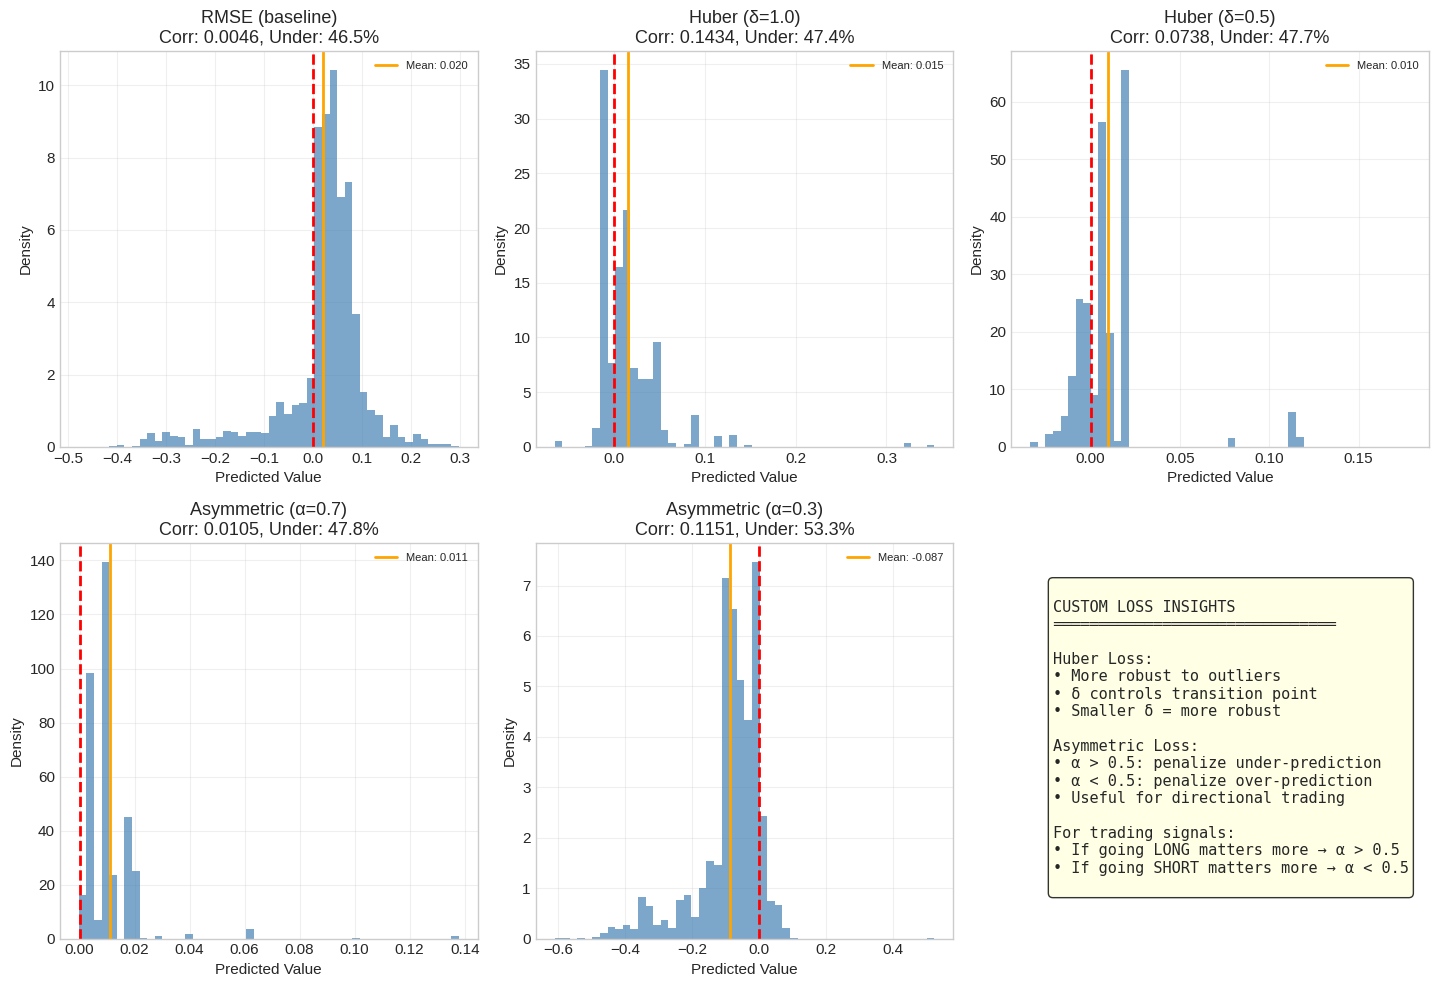

In [40]:
# Visualize custom loss effects
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Plot prediction distributions for each loss
for idx, (name, res) in enumerate(custom_results.items()):
    ax = axes[idx // 3, idx % 3]
    preds = res['preds']

    ax.hist(preds, bins=50, alpha=0.7, edgecolor='none', color='steelblue', density=True)
    ax.axvline(0, color='red', linestyle='--', linewidth=2)
    ax.axvline(np.mean(preds), color='orange', linewidth=2, label=f'Mean: {np.mean(preds):.3f}')
    ax.set_xlabel("Predicted Value")
    ax.set_ylabel("Density")
    ax.set_title(f"{name}\nCorr: {res['val_corr']:.4f}, Under: {res['pct_under']*100:.1f}%")
    ax.legend(fontsize=8)

# Use last subplot for explanation
ax = axes[1, 2]
ax.axis('off')
explanation = """
CUSTOM LOSS INSIGHTS
═══════════════════════════════

Huber Loss:
• More robust to outliers
• δ controls transition point
• Smaller δ = more robust

Asymmetric Loss:
• α > 0.5: penalize under-prediction
• α < 0.5: penalize over-prediction
• Useful for directional trading

For trading signals:
• If going LONG matters more → α > 0.5
• If going SHORT matters more → α < 0.5
"""
ax.text(0.1, 0.9, explanation, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', fontfamily='monospace',
        bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.show()

---

## 5. Feature Selection Techniques

### 5.1 Correlation-Based Feature Selection

In [41]:
# Calculate correlations with target
print("Calculating feature-target correlations...")

correlations = {}
for i, col in enumerate(feature_cols):
    corr = np.corrcoef(X_train[:, i], y_train)[0, 1]
    correlations[col] = corr if not np.isnan(corr) else 0.0

# Sort by absolute correlation
sorted_corrs = sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True)

print("\nTop 20 features by |correlation|:")
for feat, corr in sorted_corrs[:20]:
    print(f"  {feat:12s}: {corr:+.5f}")

print("\nBottom 20 features by |correlation|:")
for feat, corr in sorted_corrs[-20:]:
    print(f"  {feat:12s}: {corr:+.5f}")

Calculating feature-target correlations...

Top 20 features by |correlation|:
  X656        : -0.16345
  X652        : -0.16194
  X756        : +0.14920
  X648        : -0.14148
  X611        : +0.13566
  X653        : -0.13132
  X612        : +0.13125
  X218        : +0.13073
  X752        : +0.13066
  X684        : -0.12941
  X219        : +0.12885
  X181        : +0.12690
  X584        : +0.12613
  X590        : +0.12467
  X712        : -0.12403
  X217        : +0.12376
  X649        : -0.11919
  X754        : +0.11868
  X94         : +0.11817
  X130        : +0.11723

Bottom 20 features by |correlation|:
  X719        : -0.00107
  X156        : -0.00106
  X101        : +0.00106
  X671        : -0.00104
  X665        : -0.00099
  X723        : -0.00098
  X264        : +0.00096
  X245        : -0.00088
  X585        : -0.00087
  X526        : +0.00085
  X767        : -0.00083
  X518        : +0.00076
  X512        : +0.00062
  X396        : -0.00058
  X174        : -0.00054
  X421   

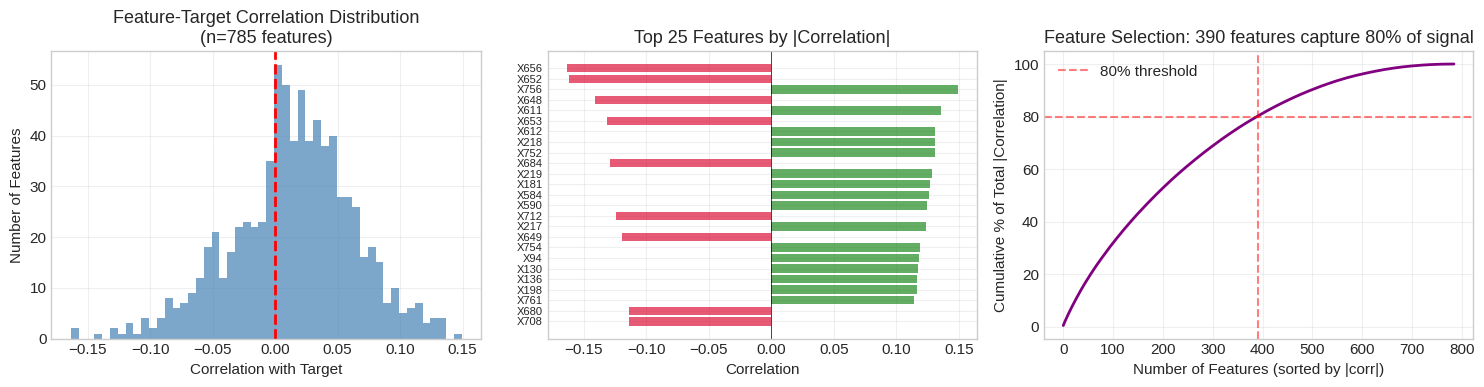

In [42]:
# Visualize correlation distribution
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

all_corrs = np.array([c for _, c in sorted_corrs])

# Distribution
ax = axes[0]
ax.hist(all_corrs, bins=50, edgecolor='none', alpha=0.7, color='steelblue')
ax.axvline(0, color='red', linestyle='--', linewidth=2)
ax.set_xlabel("Correlation with Target")
ax.set_ylabel("Number of Features")
ax.set_title(f"Feature-Target Correlation Distribution\n(n={len(all_corrs)} features)")

# Top features bar
ax = axes[1]
top_n = 25
top_feats = sorted_corrs[:top_n]
colors = ['forestgreen' if c > 0 else 'crimson' for _, c in top_feats]
ax.barh(range(top_n), [c for _, c in top_feats], color=colors, alpha=0.7)
ax.set_yticks(range(top_n))
ax.set_yticklabels([f for f, _ in top_feats], fontsize=8)
ax.axvline(0, color='black', linewidth=0.5)
ax.set_xlabel("Correlation")
ax.set_title(f"Top {top_n} Features by |Correlation|")
ax.invert_yaxis()

# Cumulative importance
ax = axes[2]
abs_corrs_sorted = np.sort(np.abs(all_corrs))[::-1]
cumsum = np.cumsum(abs_corrs_sorted) / np.sum(abs_corrs_sorted)
ax.plot(range(len(cumsum)), cumsum * 100, color='purple', linewidth=2)
ax.axhline(80, color='red', linestyle='--', alpha=0.5, label='80% threshold')
n_80 = np.argmax(cumsum >= 0.8) + 1
ax.axvline(n_80, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel("Number of Features (sorted by |corr|)")
ax.set_ylabel("Cumulative % of Total |Correlation|")
ax.set_title(f"Feature Selection: {n_80} features capture 80% of signal")
ax.legend()

plt.tight_layout()
plt.show()

### 5.2 Model-Based Feature Selection

In [43]:
# Train a baseline model to get feature importance
print("Training baseline model for feature importance...")

model_baseline = CatBoostRegressor(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    loss_function='RMSE',
    random_seed=42,
    verbose=False,
    early_stopping_rounds=50,
)
model_baseline.fit(train_pool, eval_set=val_pool, use_best_model=True, plot=False)

# Get feature importance
importance = model_baseline.get_feature_importance()
importance_dict = {feat: imp for feat, imp in zip(feature_cols, importance)}
sorted_importance = sorted(importance_dict.items(), key=lambda x: x[1], reverse=True)

print(f"Best iteration: {model_baseline.get_best_iteration()}")
print("\nTop 20 features by CatBoost importance:")
for feat, imp in sorted_importance[:20]:
    corr = correlations.get(feat, 0)
    print(f"  {feat:12s}: importance={imp:>6.2f}, corr={corr:+.4f}")

Training baseline model for feature importance...
Best iteration: 12

Top 20 features by CatBoost importance:
  X198        : importance= 19.72, corr=+0.1165
  X739        : importance=  6.70, corr=-0.0136
  X373        : importance=  6.49, corr=+0.0736
  X507        : importance=  5.56, corr=+0.0627
  X780        : importance=  3.99, corr=+0.0854
  X778        : importance=  3.17, corr=+0.0391
  X751        : importance=  3.16, corr=+0.0059
  X499        : importance=  2.75, corr=+0.0567
  X180        : importance=  2.73, corr=-0.0012
  X766        : importance=  2.58, corr=-0.0019
  X331        : importance=  2.23, corr=-0.0253
  X760        : importance=  2.10, corr=+0.0092
  X776        : importance=  1.90, corr=+0.0361
  X443        : importance=  1.84, corr=+0.0791
  X39         : importance=  1.66, corr=+0.0129
  X574        : importance=  1.39, corr=+0.0489
  X761        : importance=  1.35, corr=+0.1144
  X286        : importance=  1.33, corr=+0.0610
  X655        : importance

### 5.3 Feature Selection Comparison

Evaluating different feature subset sizes...
  n_features=  50: val_corr=0.057235
  n_features= 100: val_corr=0.071787
  n_features= 200: val_corr=0.141156
  n_features= 300: val_corr=0.143902
  n_features= 500: val_corr=0.121203
  n_features= 785: val_corr=0.041882


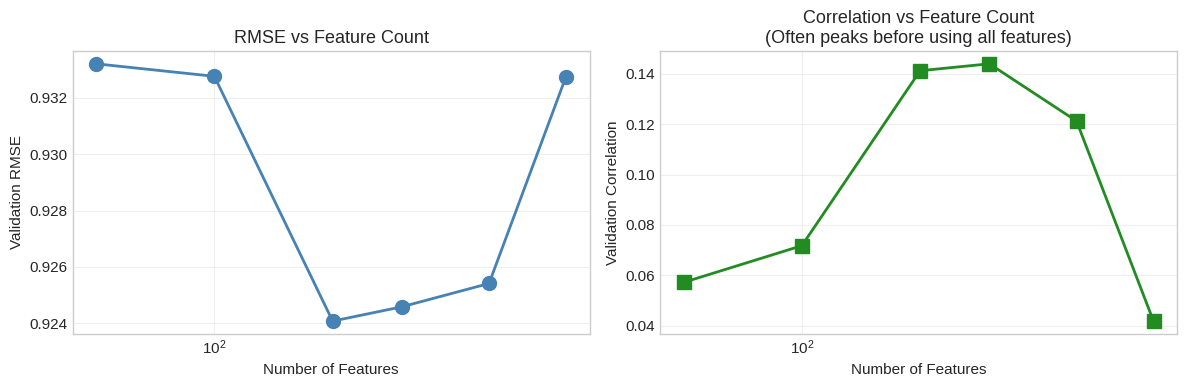


Feature Selection Summary:
-------------------------------------------------------
Best correlation achieved with 300 features: 0.143902


In [44]:
# Compare model performance with different feature subsets
n_features_list = [50, 100, 200, 300, 500, len(feature_cols)]
selection_results = {}

sorted_imp_idx = np.argsort(importance)[::-1]

print("Evaluating different feature subset sizes...")
for n_feat in n_features_list:
    selected_idx = sorted_imp_idx[:n_feat]
    selected_names = [feature_cols[i] for i in selected_idx]

    X_train_sel = X_train[:, selected_idx]
    X_val_sel = X_val[:, selected_idx]

    train_pool_sel = Pool(X_train_sel, y_train, feature_names=selected_names)
    val_pool_sel = Pool(X_val_sel, y_val, feature_names=selected_names)

    model = CatBoostRegressor(
        iterations=300,
        learning_rate=0.05,
        depth=6,
        l2_leaf_reg=3,
        loss_function='RMSE',
        random_seed=42,
        verbose=False,
        early_stopping_rounds=50,
    )
    model.fit(train_pool_sel, eval_set=val_pool_sel, use_best_model=True, plot=False)

    val_preds = model.predict(X_val_sel)

    selection_results[n_feat] = {
        'val_rmse': np.sqrt(mean_squared_error(y_val, val_preds)),
        'val_corr': np.corrcoef(y_val, val_preds)[0, 1],
        'best_iter': model.get_best_iteration(),
    }
    print(f"  n_features={n_feat:>4}: val_corr={selection_results[n_feat]['val_corr']:.6f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

n_list = list(selection_results.keys())
rmses = [selection_results[n]['val_rmse'] for n in n_list]
corrs = [selection_results[n]['val_corr'] for n in n_list]

ax = axes[0]
ax.plot(n_list, rmses, 'o-', color='steelblue', linewidth=2, markersize=10)
ax.set_xlabel("Number of Features")
ax.set_ylabel("Validation RMSE")
ax.set_title("RMSE vs Feature Count")
ax.set_xscale('log')

ax = axes[1]
ax.plot(n_list, corrs, 's-', color='forestgreen', linewidth=2, markersize=10)
ax.set_xlabel("Number of Features")
ax.set_ylabel("Validation Correlation")
ax.set_title("Correlation vs Feature Count\n(Often peaks before using all features)")
ax.set_xscale('log')

plt.tight_layout()
plt.show()

print("\nFeature Selection Summary:")
print("-" * 55)
best_n = max(selection_results.keys(), key=lambda k: selection_results[k]['val_corr'])
print(f"Best correlation achieved with {best_n} features: {selection_results[best_n]['val_corr']:.6f}")

### 5.4 Explainability: SHAP and Partial Dependence

SHAP values give local and global feature impact, but are expensive. We sample a subset.

In [45]:
# SHAP values (sampled)
sample_size = min(2000, len(X_val))
sample_idx = np.random.choice(len(X_val), sample_size, replace=False)
X_val_sample = X_val[sample_idx]
y_val_sample = y_val[sample_idx]
val_pool_sample = Pool(X_val_sample, y_val_sample, feature_names=feature_cols)

shap_values = model_baseline.get_feature_importance(val_pool_sample, type="ShapValues")
mean_abs_shap = np.mean(np.abs(shap_values[:, :-1]), axis=0)  # last column is expected value

shap_df = pd.DataFrame(
    {"feature": feature_cols, "mean_abs_shap": mean_abs_shap}
).sort_values("mean_abs_shap", ascending=False)
shap_df.head(20)

,feature,mean_abs_shap
202,X198,0.018486
377,X373,0.012203
576,X572,0.006746
770,X766,0.006365
782,X778,0.006254
292,X288,0.006178
511,X507,0.005779
290,X286,0.005713
582,X578,0.005600
755,X751,0.005402


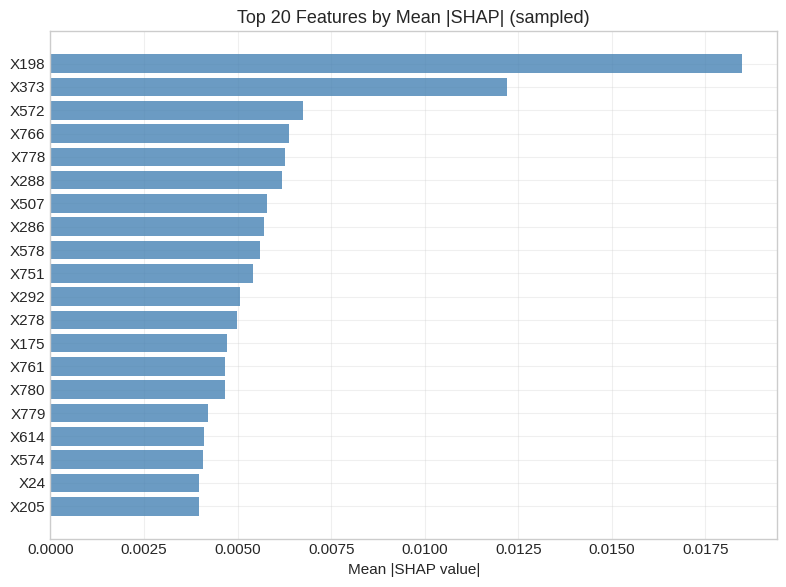

In [46]:
# Plot top SHAP features
top_shap = shap_df.head(20).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_shap["feature"], top_shap["mean_abs_shap"], color="steelblue", alpha=0.8)
plt.xlabel("Mean |SHAP value|")
plt.title("Top 20 Features by Mean |SHAP| (sampled)")
plt.tight_layout()
plt.show()

Partial dependence shows average marginal effects, but assumes feature independence.

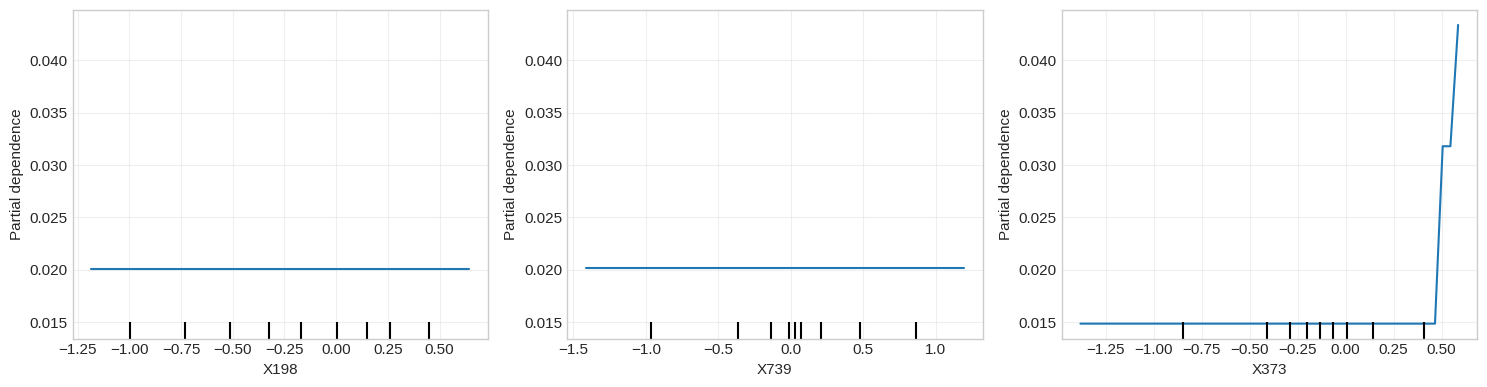

In [47]:
# Partial dependence for top features
top_features_pdp = [feat for feat, _ in sorted_importance[:3]]
X_val_df = pd.DataFrame(X_val, columns=feature_cols)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(
    model_baseline,
    X_val_df,
    features=top_features_pdp,
    grid_resolution=50,
    ax=ax,
)
plt.tight_layout()
plt.show()

---

## 6. Trading Simulation and Backtesting

### 6.1 Simple Trading Strategy

We'll implement a simple strategy:
- **Signal**: Model prediction > threshold → LONG position
- **Hold period**: 5 rows (assumes evenly spaced samples)
- **PnL**: Sum of labels during holding period (treat label as return proxy)
  
This is a toy backtest for intuition only (no slippage model, queue priority, or realistic execution).

In [48]:
def backtest_strategy(
    predictions,
    actuals,
    threshold=0.0,
    hold_period=5,
    transaction_cost=0.0,
    periods_per_year=None,
):
    """
    Backtest a simple threshold-based trading strategy.

    Args:
        predictions: Model predictions (signals)
        actuals: Actual labels (future return proxy)
        threshold: Enter position when |pred| > threshold
        hold_period: How many periods to hold position
        transaction_cost: Cost per trade (as fraction of return)
        periods_per_year: If provided, annualize Sharpe using this frequency

    Returns:
        dict with PnL, Sharpe, trades, etc.
    """
    n = len(predictions)
    pnl = np.zeros(n)
    positions = np.zeros(n)  # 1=long, -1=short, 0=flat
    trades = []

    i = 0
    while i < n - hold_period:
        signal = predictions[i]

        if abs(signal) > threshold:
            # Enter position
            direction = 1 if signal > 0 else -1
            positions[i:i+hold_period] = direction

            # Calculate PnL for this trade
            trade_pnl = direction * np.sum(actuals[i:i+hold_period]) - transaction_cost
            pnl[i] = trade_pnl

            trades.append({
                'entry': i,
                'exit': i + hold_period,
                'direction': direction,
                'signal': signal,
                'pnl': trade_pnl,
            })

            i += hold_period  # Skip to after this trade
        else:
            i += 1

    # Calculate metrics
    cumulative_pnl = np.cumsum(pnl)
    trade_pnls = [t['pnl'] for t in trades] if trades else [0]

    # Sharpe ratio (per-trade by default; annualized if periods_per_year is set)
    returns_per_trade = np.array(trade_pnls)
    if len(returns_per_trade) > 1 and np.std(returns_per_trade) > 0:
        sharpe = np.mean(returns_per_trade) / np.std(returns_per_trade)
        if periods_per_year is not None:
            sharpe *= np.sqrt(periods_per_year / hold_period)
    else:
        sharpe = 0.0

    return {
        'total_pnl': np.sum(pnl),
        'n_trades': len(trades),
        'win_rate': np.mean([t['pnl'] > 0 for t in trades]) if trades else 0,
        'avg_pnl': np.mean(trade_pnls),
        'sharpe': sharpe,
        'max_drawdown': np.min(cumulative_pnl - np.maximum.accumulate(cumulative_pnl)),
        'cumulative_pnl': cumulative_pnl,
        'positions': positions,
        'trades': trades,
    }


# First, let's see what ideal prediction would look like
print("="*70)
print("IDEAL PREDICTION ANALYSIS")
print("="*70)
print("\nWhat if we had perfect foresight? Testing different hold periods...")

hold_periods = [1, 3, 5, 10, 15, 30]
ideal_results = {}

for hold in hold_periods:
    # Ideal signal = actual future return
    result = backtest_strategy(y_val, y_val, threshold=0.1, hold_period=hold, periods_per_year=365)
    ideal_results[hold] = result
    print(f"  Hold={hold:>2} rows: Sharpe={result['sharpe']:>8.2f}, "
          f"Trades={result['n_trades']:>5}, Win={result['win_rate']*100:.1f}%")

print("\n→ This helps us choose the right holding period for our model!")

IDEAL PREDICTION ANALYSIS

What if we had perfect foresight? Testing different hold periods...
  Hold= 1 rows: Sharpe=   19.27, Trades=17311, Win=100.0%
  Hold= 3 rows: Sharpe=   10.51, Trades= 6111, Win=98.4%
  Hold= 5 rows: Sharpe=    7.89, Trades= 3761, Win=96.6%
  Hold=10 rows: Sharpe=    5.19, Trades= 1925, Win=92.2%
  Hold=15 rows: Sharpe=    3.92, Trades= 1302, Win=89.4%
  Hold=30 rows: Sharpe=    2.44, Trades=  657, Win=82.8%

→ This helps us choose the right holding period for our model!


### 6.2 Model-Based Trading Backtest

In [49]:
# Get predictions from our baseline model
val_predictions = model_baseline.predict(X_val)

# Test different thresholds and hold periods
thresholds = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
hold_periods = [1, 5, 10]

print("="*70)
print("MODEL PREDICTION BACKTEST")
print("="*70)

backtest_results = {}
for hold in hold_periods:
    backtest_results[hold] = {}
    for thresh in thresholds:
        result = backtest_strategy(val_predictions, y_val, threshold=thresh, hold_period=hold)
        backtest_results[hold][thresh] = result

# Print summary table
print("\nBacktest Results (Sharpe Ratio):")
sharpe_table = pd.DataFrame(
    {
        f"{t:.2f}": [backtest_results[h][t]["sharpe"] for h in hold_periods]
        for t in thresholds
    },
    index=[f"{h} rows" for h in hold_periods],
)
sharpe_table

print("\n# Trades:")
trades_table = pd.DataFrame(
    {
        f"{t:.2f}": [backtest_results[h][t]["n_trades"] for h in hold_periods]
        for t in thresholds
    },
    index=[f"{h} rows" for h in hold_periods],
)
trades_table

MODEL PREDICTION BACKTEST

Backtest Results (Sharpe Ratio):

# Trades:


,0.00,0.05,0.10,0.15,0.20,0.30
1 rows,19999,9469,3132,1849,1131,356
5 rows,3999,2019,705,416,265,87
10 rows,1999,1052,379,223,148,50


### 6.3 Trading Visualization

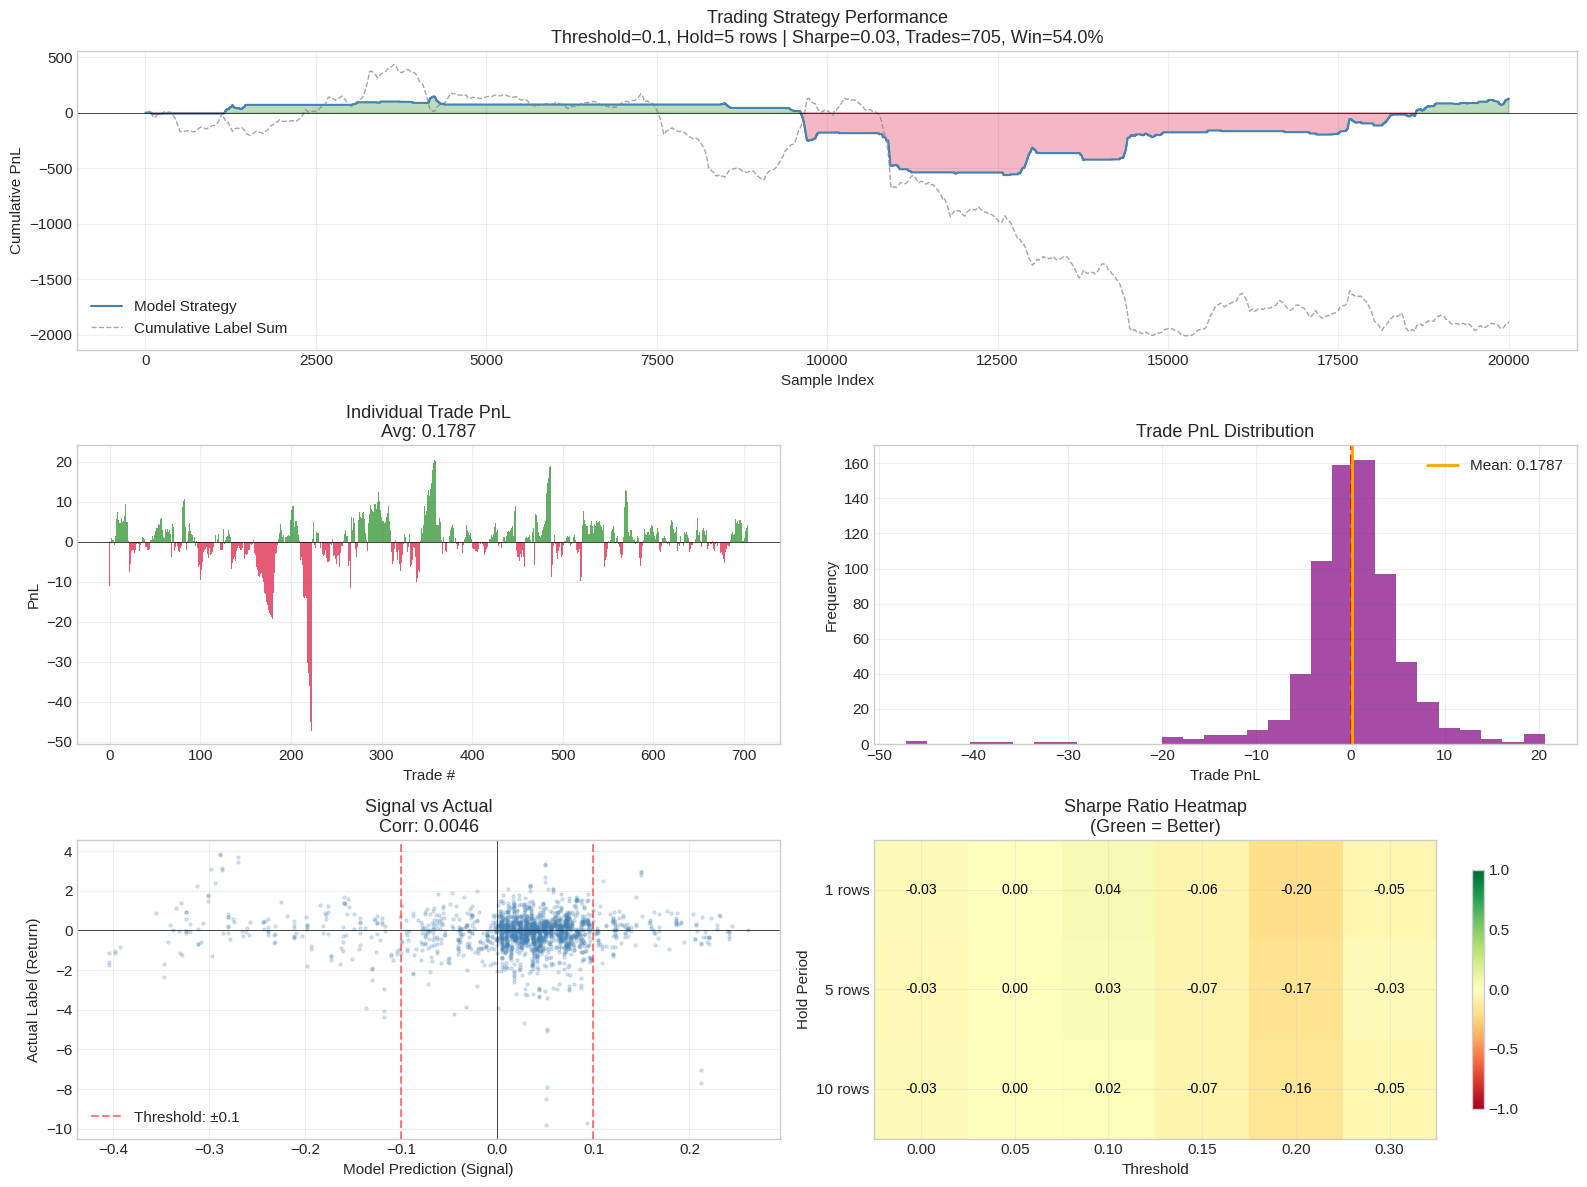

In [50]:
# Detailed visualization for best strategy
best_hold = 5
best_thresh = 0.1
result = backtest_results[best_hold][best_thresh]

fig = plt.figure(figsize=(16, 12))
gs = GridSpec(3, 2, figure=fig)

# 1. Cumulative PnL
ax = fig.add_subplot(gs[0, :])
cumulative_pnl = result['cumulative_pnl']
ax.plot(cumulative_pnl, color='steelblue', linewidth=1.5, label='Model Strategy')

# Compare to cumulative label sum (not a tradable baseline)
buy_hold_pnl = np.cumsum(y_val)
ax.plot(buy_hold_pnl, color='gray', linestyle='--', alpha=0.7, linewidth=1,
        label='Cumulative Label Sum')

ax.axhline(0, color='black', linewidth=0.5)
ax.fill_between(range(len(cumulative_pnl)), 0, cumulative_pnl,
                where=cumulative_pnl > 0, alpha=0.3, color='forestgreen')
ax.fill_between(range(len(cumulative_pnl)), 0, cumulative_pnl,
                where=cumulative_pnl < 0, alpha=0.3, color='crimson')
ax.set_xlabel("Sample Index")
ax.set_ylabel("Cumulative PnL")
ax.set_title(f"Trading Strategy Performance\n"
             f"Threshold={best_thresh}, Hold={best_hold} rows | "
             f"Sharpe={result['sharpe']:.2f}, Trades={result['n_trades']}, Win={result['win_rate']*100:.1f}%")
ax.legend()

# 2. Trade distribution
ax = fig.add_subplot(gs[1, 0])
if result['trades']:
    trade_pnls = [t['pnl'] for t in result['trades']]
    colors = ['forestgreen' if p > 0 else 'crimson' for p in trade_pnls]
    ax.bar(range(len(trade_pnls)), trade_pnls, color=colors, alpha=0.7, width=1)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_xlabel("Trade #")
    ax.set_ylabel("PnL")
    ax.set_title(f"Individual Trade PnL\nAvg: {np.mean(trade_pnls):.4f}")

# 3. PnL distribution
ax = fig.add_subplot(gs[1, 1])
if result['trades']:
    ax.hist(trade_pnls, bins=30, edgecolor='none', alpha=0.7, color='purple')
    ax.axvline(0, color='red', linestyle='--', linewidth=2)
    ax.axvline(np.mean(trade_pnls), color='orange', linewidth=2, label=f'Mean: {np.mean(trade_pnls):.4f}')
    ax.set_xlabel("Trade PnL")
    ax.set_ylabel("Frequency")
    ax.set_title("Trade PnL Distribution")
    ax.legend()

# 4. Signal vs Actual scatter
ax = fig.add_subplot(gs[2, 0])
sample_n = min(2000, len(val_predictions))
sample_idx = np.random.choice(len(val_predictions), sample_n, replace=False)
ax.scatter(val_predictions[sample_idx], y_val[sample_idx], alpha=0.2, s=5, c='steelblue')
ax.axhline(0, color='black', linewidth=0.5)
ax.axvline(0, color='black', linewidth=0.5)
ax.axvline(best_thresh, color='red', linestyle='--', alpha=0.5, label=f'Threshold: ±{best_thresh}')
ax.axvline(-best_thresh, color='red', linestyle='--', alpha=0.5)
ax.set_xlabel("Model Prediction (Signal)")
ax.set_ylabel("Actual Label (Return)")
ax.set_title(f"Signal vs Actual\nCorr: {np.corrcoef(val_predictions, y_val)[0,1]:.4f}")
ax.legend()

# 5. Sharpe by threshold heatmap
ax = fig.add_subplot(gs[2, 1])
sharpe_matrix = np.array([[backtest_results[h][t]['sharpe'] for t in thresholds] for h in hold_periods])
im = ax.imshow(sharpe_matrix, cmap='RdYlGn', aspect='auto', vmin=-1, vmax=1)
ax.set_xticks(range(len(thresholds)))
ax.set_yticks(range(len(hold_periods)))
ax.set_xticklabels([f'{t:.2f}' for t in thresholds])
ax.set_yticklabels([f'{h} rows' for h in hold_periods])
ax.set_xlabel("Threshold")
ax.set_ylabel("Hold Period")
ax.set_title("Sharpe Ratio Heatmap\n(Green = Better)")

for i in range(len(hold_periods)):
    for j in range(len(thresholds)):
        ax.text(j, i, f'{sharpe_matrix[i,j]:.2f}', ha='center', va='center',
                color='white' if abs(sharpe_matrix[i,j]) > 0.3 else 'black', fontsize=10)

plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

---

## 7. Final Model Training and Evaluation

### 7.1 Optimized Model with Best Parameters

Note: `iterations` is a maximum; with `early_stopping_rounds`, CatBoost keeps the best iteration found on validation.

In [51]:
# Based on our experiments, train final model with best settings
final_params = {
    'iterations': 500,
    'learning_rate': 0.03,
    'depth': 6,
    'l2_leaf_reg': 5,
    'min_data_in_leaf': 50,
    'grow_policy': 'SymmetricTree',
    'loss_function': 'RMSE',
    'random_seed': 42,
    'verbose': 100,
    'early_stopping_rounds': 100,
}

print("Training final model...")
print("-" * 60)
model_final = CatBoostRegressor(**final_params)
model_final.fit(train_pool, eval_set=val_pool, use_best_model=True, plot=False)
print("-" * 60)
print(f"Best iteration: {model_final.get_best_iteration()}")

# Evaluate on all sets
def evaluate(model, X, y, name):
    preds = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, preds))
    mae = mean_absolute_error(y, preds)
    corr = np.corrcoef(y, preds)[0, 1]
    r2 = r2_score(y, preds)
    return {'rmse': rmse, 'mae': mae, 'corr': corr, 'r2': r2, 'preds': preds}

print("\n" + "="*60)
print("FINAL MODEL EVALUATION")
print("="*60)

train_eval = evaluate(model_final, X_train, y_train, "Train")
val_eval = evaluate(model_final, X_val, y_val, "Validation")
test_eval = evaluate(model_final, X_test, y_test, "Test")

final_eval_df = pd.DataFrame(
    [
        {"Set": "Train", **train_eval},
        {"Set": "Validation", **val_eval},
        {"Set": "Test", **test_eval},
    ]
)[["Set", "rmse", "mae", "corr", "r2"]].rename(
    columns={"rmse": "RMSE", "mae": "MAE", "corr": "Corr", "r2": "R2"}
)
final_eval_df

Training final model...
------------------------------------------------------------
0:	learn: 0.9898288	test: 0.9365945	best: 0.9365945 (0)	total: 216ms	remaining: 1m 47s
100:	learn: 0.6909100	test: 0.9576412	best: 0.9259693 (23)	total: 18.7s	remaining: 1m 13s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9259692932
bestIteration = 23

Shrink model to first 24 iterations.
------------------------------------------------------------
Best iteration: 23

FINAL MODEL EVALUATION


,Set,RMSE,MAE,Corr,R2
0,Train,0.882350,0.567198,0.650777,0.215362
1,Validation,0.925969,0.617334,0.115936,-0.004475
2,Test,1.077152,0.652395,0.178761,0.019481


### 7.2 Comprehensive Final Visualization

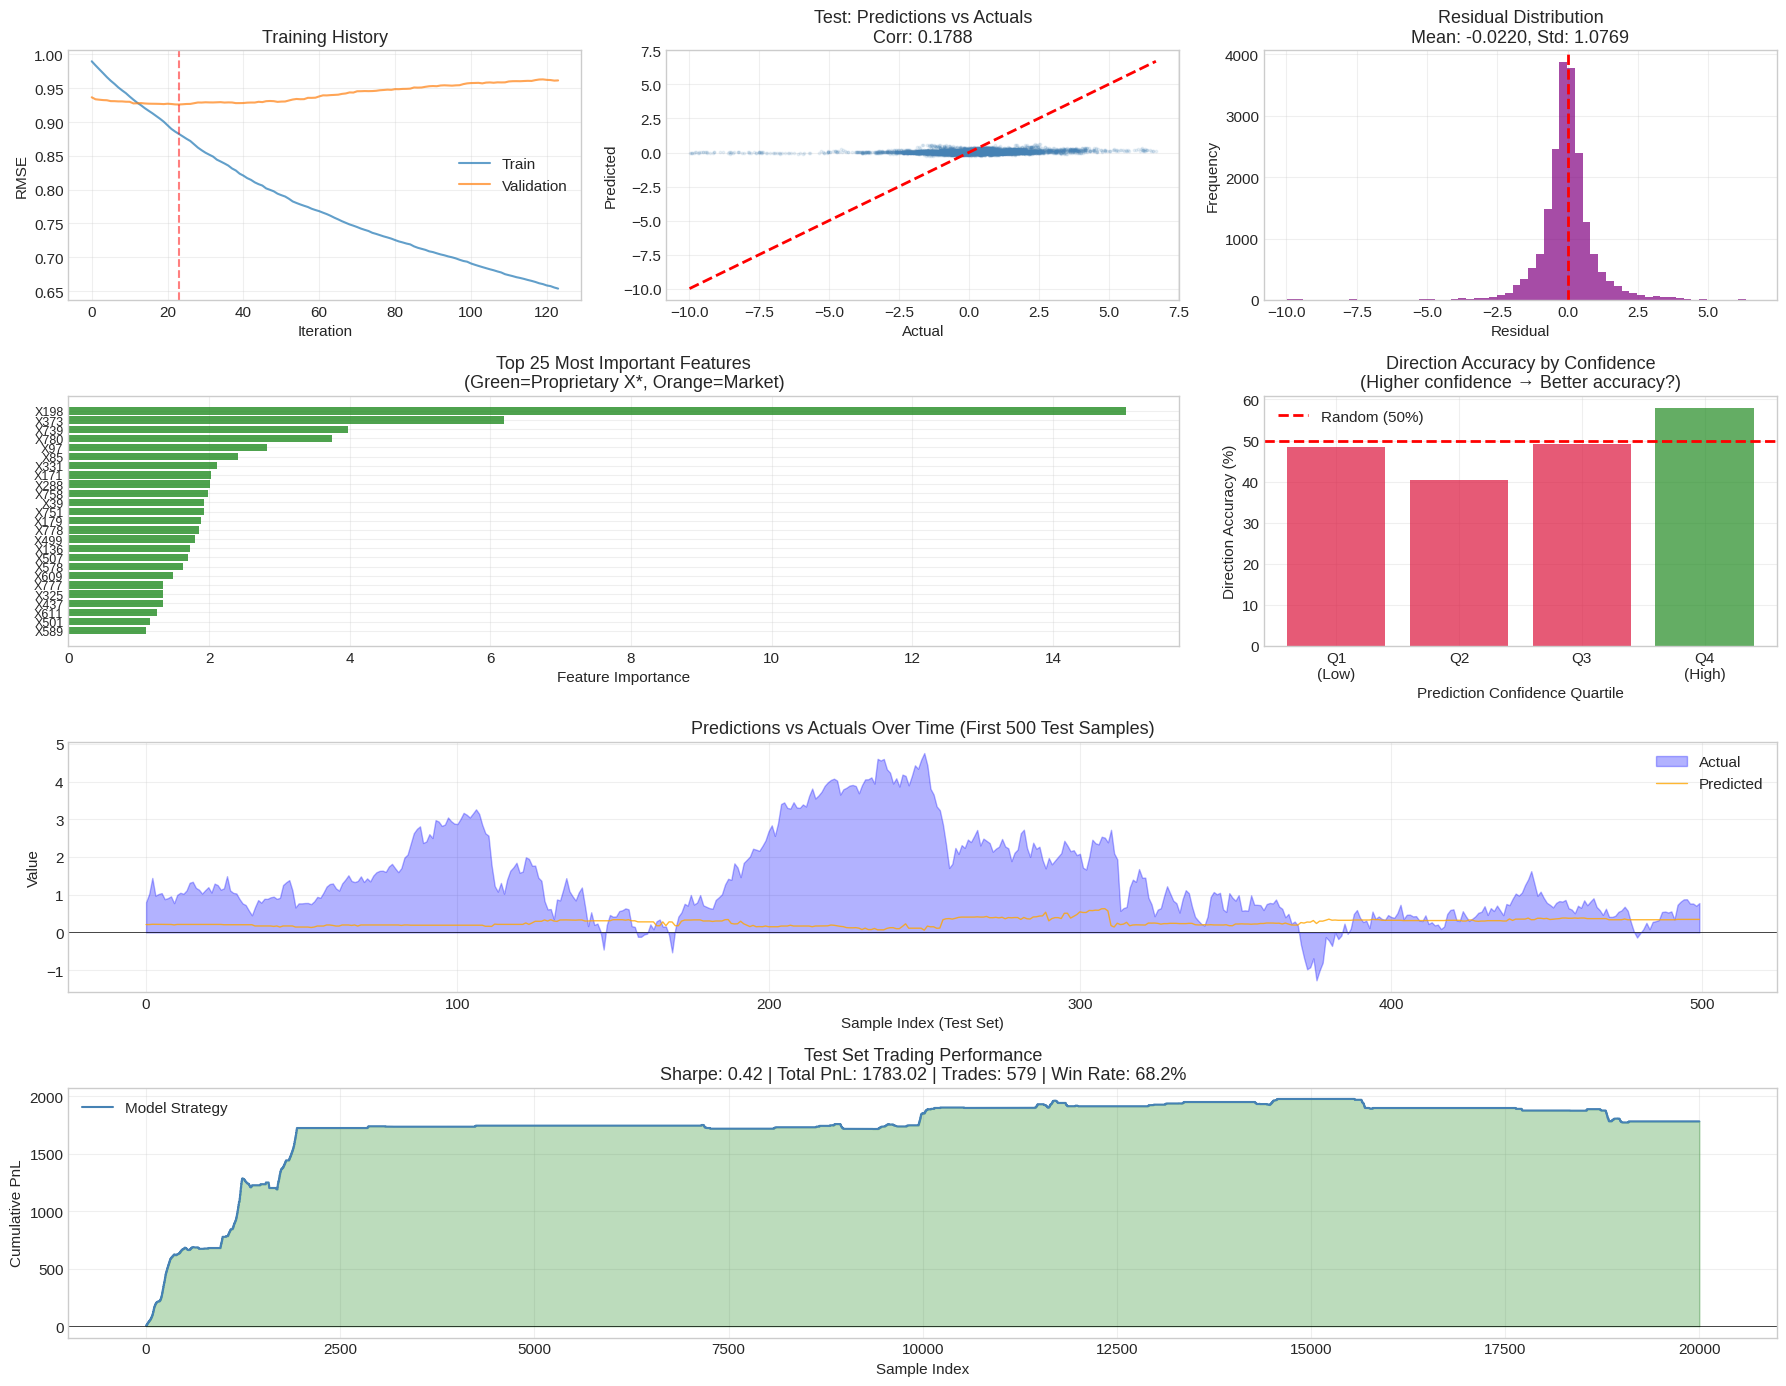

In [52]:
fig = plt.figure(figsize=(18, 14))
gs = GridSpec(4, 3, figure=fig)

test_preds = test_eval['preds']

# 1. Training history
ax = fig.add_subplot(gs[0, 0])
evals = model_final.get_evals_result()
ax.plot(evals['learn']['RMSE'], label='Train', alpha=0.7)
ax.plot(evals['validation']['RMSE'], label='Validation', alpha=0.7)
ax.axvline(model_final.get_best_iteration(), color='red', linestyle='--', alpha=0.5)
ax.set_xlabel("Iteration")
ax.set_ylabel("RMSE")
ax.set_title("Training History")
ax.legend()

# 2. Predictions vs Actuals (Test)
ax = fig.add_subplot(gs[0, 1])
ax.scatter(y_test, test_preds, alpha=0.1, s=3, c='steelblue')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', linewidth=2)
ax.set_xlabel("Actual")
ax.set_ylabel("Predicted")
ax.set_title(f"Test: Predictions vs Actuals\nCorr: {test_eval['corr']:.4f}")

# 3. Residuals
ax = fig.add_subplot(gs[0, 2])
residuals = y_test - test_preds
ax.hist(residuals, bins=60, edgecolor='none', alpha=0.7, color='purple')
ax.axvline(0, color='red', linestyle='--', linewidth=2)
ax.set_xlabel("Residual")
ax.set_ylabel("Frequency")
ax.set_title(f"Residual Distribution\nMean: {np.mean(residuals):.4f}, Std: {np.std(residuals):.4f}")

# 4. Feature importance (top 25)
ax = fig.add_subplot(gs[1, :2])
importance = model_final.get_feature_importance()
sorted_idx = np.argsort(importance)[::-1][:25]
top_features = [feature_cols[i] for i in sorted_idx]
top_importance = importance[sorted_idx]
colors = ['forestgreen' if f.startswith('X') else 'coral' for f in top_features]
ax.barh(range(25), top_importance, color=colors, alpha=0.8)
ax.set_yticks(range(25))
ax.set_yticklabels(top_features, fontsize=9)
ax.set_xlabel("Feature Importance")
ax.set_title("Top 25 Most Important Features\n(Green=Proprietary X*, Orange=Market)")
ax.invert_yaxis()

# 5. Direction accuracy by prediction confidence
ax = fig.add_subplot(gs[1, 2])
pred_abs = np.abs(test_preds)
quantiles = [0, 25, 50, 75, 100]
q_vals = np.percentile(pred_abs, quantiles)
direction_acc = []
for i in range(len(quantiles)-1):
    mask = (pred_abs >= q_vals[i]) & (pred_abs < q_vals[i+1])
    if np.sum(mask) > 0:
        correct = np.sign(y_test[mask]) == np.sign(test_preds[mask])
        direction_acc.append(np.mean(correct))
    else:
        direction_acc.append(0.5)

colors = ['forestgreen' if a > 0.5 else 'crimson' for a in direction_acc]
ax.bar(range(4), [a*100 for a in direction_acc], color=colors, alpha=0.7)
ax.axhline(50, color='red', linestyle='--', linewidth=2, label='Random (50%)')
ax.set_xticks(range(4))
ax.set_xticklabels(['Q1\n(Low)', 'Q2', 'Q3', 'Q4\n(High)'])
ax.set_xlabel("Prediction Confidence Quartile")
ax.set_ylabel("Direction Accuracy (%)")
ax.set_title("Direction Accuracy by Confidence\n(Higher confidence → Better accuracy?)")
ax.legend()

# 6. Predictions over time (sample)
ax = fig.add_subplot(gs[2, :])
sample_n = min(500, len(test_preds))
ax.fill_between(range(sample_n), y_test[:sample_n], alpha=0.3, label='Actual', color='blue')
ax.plot(range(sample_n), test_preds[:sample_n], alpha=0.8, linewidth=1, label='Predicted', color='orange')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel("Sample Index (Test Set)")
ax.set_ylabel("Value")
ax.set_title("Predictions vs Actuals Over Time (First 500 Test Samples)")
ax.legend()

# 7. Trading backtest on test set
ax = fig.add_subplot(gs[3, :])
test_backtest = backtest_strategy(test_preds, y_test, threshold=0.1, hold_period=5)
cum_pnl = test_backtest['cumulative_pnl']
ax.plot(cum_pnl, color='steelblue', linewidth=1.5, label='Model Strategy')
ax.fill_between(range(len(cum_pnl)), 0, cum_pnl,
                where=cum_pnl > 0, alpha=0.3, color='forestgreen')
ax.fill_between(range(len(cum_pnl)), 0, cum_pnl,
                where=cum_pnl < 0, alpha=0.3, color='crimson')
ax.axhline(0, color='black', linewidth=0.5)
ax.set_xlabel("Sample Index")
ax.set_ylabel("Cumulative PnL")
ax.set_title(f"Test Set Trading Performance\n"
             f"Sharpe: {test_backtest['sharpe']:.2f} | "
             f"Total PnL: {test_backtest['total_pnl']:.2f} | "
             f"Trades: {test_backtest['n_trades']} | "
             f"Win Rate: {test_backtest['win_rate']*100:.1f}%")
ax.legend()

plt.tight_layout()
plt.show()

---

## 8. Summary and Key Takeaways

- **Data exploration**: Polars for 500k+ rows, market microstructure plots, low signal-to-noise target.
- **CatBoost parameters**: `min_data_in_leaf` and `grow_policy` control complexity; `l2_leaf_reg` ties to `w* = -G/(H+λ)`.
- **Custom losses**: Huber for outliers, asymmetric for directional costs; implement `calc_ders_range`.
- **Feature selection**: correlation filter + model importance often beat using all features.
- **Trading simulation**: threshold strategy, Sharpe/PnL/win rate across hold periods.
- **Lecture connection**: 2nd-order Taylor expansion, ordered boosting to reduce target-stat leakage for categorical features.

Remember: set `USE_SUBSET=False` to train on full data for the final model.

Seminar complete! Happy boosting!